# 🤗 Hugging Face: from pretrained checkpoints to your own fine-tuned model

### Human Language Technologies 2026-27 · Lab

In the last labs we **built** things from scratch: count tables, word2vec, a tiny GPT. Today we stop building transformers and start **borrowing** them. Thousands of pretrained models are one line of code away on the Hugging Face Hub; the hard part is to use them _well_.

The notebook has two halves:

|           | Part I: open the boxes                                                                         | Part II: a mini-project                                                                       |
| --------- | ---------------------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------------- |
| Question  | what is inside a `pipeline`?                                                                   | can a fine-tuned BERT beat TF-IDF on _our_ movie reviews?                                     |
| Models    | BERT (encoder), GPT-2 and a small chat model (decoders)                                        | DistilBERT + a classification head, full fine-tuning and LoRA                                 |
| You learn | tokenizers, model classes, heads, masked LM, contextual embeddings, `generate`, chat templates | datasets, baselines, splits, `Trainer`, learning curves, error analysis, significance, saving |

The movie reviews are an old friend: the same 2,000 reviews (and the **same train/test split**) of the NLTK lab, where VADER, logistic regression on bag of words and an off-the-shelf DistilBERT fought for the first place. Today the scoreboard gets new contenders.

### 🎯 Learning goals

By the end of the notebook you should be able to:

- explain what a `pipeline` does in three steps (**tokenizer → model → post-processing**) and redo them by hand;
- read a tokenizer's output: **subword tokens**, special tokens (`[CLS]`, `[SEP]`, `[MASK]`, `<|im_start|>`), `input_ids`, `attention_mask`, padding and truncation;
- load the right **Auto class** for a task and say which parameters are pretrained and which are a new, randomly initialized **head**;
- use an **encoder** (BERT): masked language modeling, contextual embeddings, attention weights;
- use a **decoder**: next-token probabilities, `generate` with greedy/top-k/top-p sampling, and **chat templates** for instruction-tuned models;
- run a fine-tuning project the way it should be run: **baselines first**, train/validation/test discipline, `Trainer`, learning curves, error analysis, a significance test, saving and reloading; and **LoRA** when the model is too big to fine-tune entirely.

You will use similar tools in your **group projects**.


> 🔍 **Lectures and reading.** Part I follows Lectures 14–15 (_Transformers_, SLP Ch. 7: the transformer block, the language modeling head, decoding), Lecture 17 (_Pretraining_), Lecture 18 (_Post-training_, SLP Ch. 8: instruction tuning §8.1, parameter-efficient fine-tuning and LoRA §8.2) and Lecture 20 (_From tokens to reasoners_: tokenizers in practice, base models vs assistants, supervised fine-tuning with the prompt tokens masked out, chat templates, hallucinations). Section 3 introduces **bidirectional encoders** (BERT), which we have not seen in the lectures yet: it gives what you need to use them, and SLP Ch. 9 has the full story (masked language models, the masking recipe §9.3.1, fine-tuning for classification §9.4). Subword tokenization with byte-pair encoding is Lecture 02 (SLP Ch. 2). Part II reuses the evaluation toolkit of Lectures 06–07 (precision, recall, F1, the paired bootstrap) and the movie-review experiments of the NLTK lab (L09) and of the word embeddings lab (L12).


# 🧪 0. Setup

In Colab, choose **Runtime → Change runtime type → T4 GPU**. Part I runs fine on CPU; Part II **fine-tunes** a 66-million-parameter model, which takes a few minutes on a GPU and much longer on CPU. On CPU the notebook automatically switches to a smaller budget (shorter inputs, fewer epochs), so expect lower scores.

The setup cell makes sure that a recent version of the libraries is installed:

- `transformers`: models, tokenizers, `pipeline`, `Trainer`;
- `datasets`: datasets with fast, cached `map`;
- `peft`: parameter-efficient fine-tuning (LoRA);
- `accelerate`: used by `Trainer` under the hood.

pip may print an `ERROR: pip's dependency resolver ...` message about packages preinstalled in Colab that we do not use (e.g. `cudf` and `pyarrow`): it is harmless, ignore it. The cell also uninstalls `torchao`: Colab ships an old version that makes recent `peft` crash, and we do not need it.

> 🔍 **Versions matter.** This notebook uses `transformers` **v5**. Many tutorials on the web were written for v4: if you copy code from them, expect renamed arguments (`evaluation_strategy` → `eval_strategy`, `Trainer(tokenizer=...)` → `Trainer(processing_class=...)`, `torch_dtype` → `dtype`) and a few pipelines that no longer exist (`summarization`, `translation`, `question-answering`: in v5 you call the model's `generate` directly, or use a chat model).


In [ ]:
# 🧪 Setup (just run it): installs/updates the libraries (~1 min), imports them, fixes the seeds,
# and defines the helpers used by the 🧪 check cells of the Exercises at the end
!pip -q install -U "transformers>=5.0" datasets accelerate peft
!pip -q uninstall -y torchao          # Colab ships an old torchao that makes the new peft fail (LoRA, Section 5.13); we do not use it

import json
import math
import os
import random
import re
import shutil
import time
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
from IPython.display import display

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
transformers.set_seed(SEED)  # seeds Python, NumPy and PyTorch (CPU and GPU) at once

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ON_GPU = DEVICE == "cuda"
nltk.download("movie_reviews", quiet=True)


# Helpers for the 🧪 check cells of the Exercises: ✅ correct · ❌ something is off · ⏳ not implemented yet
def _ok(msg):
    print("✅", msg)


def _fail(msg):
    print("❌", msg)


def _todo(name):
    print(f"⏳ {name}: not implemented yet (your function returned None).")


def _err(e):
    _fail(f"your code raised {type(e).__name__}: {e}")


def print_encoding(enc):
    # pretty-print what a tokenizer returns: one line per key
    for k, v in enc.items():
        print(f"{k:15s}: {v}")


print(
    "transformers:",
    transformers.__version__,
    "| torch:",
    torch.__version__,
    "| device:",
    DEVICE,
)
if ON_GPU:
    print("GPU:", torch.cuda.get_device_name(0))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
transformers: 5.21.0 | torch: 2.11.0+cu130 | device: cuda
GPU: Tesla T4


> 🔍 **No account needed.** All the models of this notebook are public: you can download them without logging in (Colab may print a warning about an `HF_TOKEN` secret: ignore it). You need a free Hugging Face account and a token only to **upload** your own models, and for a few _gated_ models (Llama, Gemma, ...) whose licence you must accept on their web page first.


# 🏪 1. The Hub and the pipeline

The [Hugging Face Hub](https://huggingface.co/models) hosts models (weights + configuration + tokenizer), [datasets](https://huggingface.co/datasets), and demos. Every model has a name `organization/model` and a **model card**: read it! It says what the model was trained on, for which task, with which labels, under which licence, and with which known limitations.

In the NLTK lab we met the `pipeline` as a black box.
Just select the task you're interested: https://huggingface.co/tasks (like `text-classification`, `token-classification`, `fill-mask`, `summarization`, `question-answering`, etc).

Here it is again, on the same sentiment model (DistilBERT fine-tuned on **SST-2**, a dataset of sentences from movie reviews):


In [ ]:
from transformers import pipeline

SST2 = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"  # always name the model explicitly
classifier = pipeline("text-classification", model=SST2, device=DEVICE)

classifier([
    "I've been waiting for a Hugging Face lab my whole life.",
    "The plot was predictable and the acting was wooden.",
    "Not bad at all.",
])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9721760749816895},
 {'label': 'NEGATIVE', 'score': 0.9998109936714172},
 {'label': 'POSITIVE', 'score': 0.99928218126297}]

> 🔍 **Always name the model.** `pipeline("text-classification")` without `model=` also works: it downloads a default model and prints a warning. Defaults can change between library versions, so your results would silently change too. In a project, the model name (and ideally its _revision_) is part of the experimental setup, like the random seed.

One function, many tasks. The same `pipeline` interface works for tasks with very different outputs. Two more from the encoder family, before we open the box:


In [ ]:
# Named entity recognition (Lecture 08, SLP Ch. 18): a BERT fine-tuned on CoNLL-2003, one BIO tag per token
ner = pipeline(
    "token-classification",
    model="dslim/bert-base-NER",
    aggregation_strategy="simple",
    device=DEVICE,
)  # "simple": merge the subword tokens and B-/I- tags into spans
ner(
    "My name is Andrea, I studied at the University of Exeter, and now I work at the University of Pisa."
)

config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9987288),
  'word': 'Andrea',
  'start': 11,
  'end': 17},
 {'entity_group': 'ORG',
  'score': np.float32(0.9941146),
  'word': 'University of Exeter',
  'start': 36,
  'end': 56},
 {'entity_group': 'ORG',
  'score': np.float32(0.99648446),
  'word': 'University of Pisa',
  'start': 80,
  'end': 98}]

In [4]:
# Masked language modeling (SLP Ch. 9): the pretraining task of BERT
unmasker = pipeline("fill-mask", model="google-bert/bert-base-uncased", device=DEVICE)
unmasker("The goal of this course is to teach you all about [MASK] models.", top_k=5)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: google-bert/bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[{'score': 0.42615920305252075,
  'token': 2535,
  'token_str': 'role',
  'sequence': 'the goal of this course is to teach you all about role models.'},
 {'score': 0.14519774913787842,
  'token': 2449,
  'token_str': 'business',
  'sequence': 'the goal of this course is to teach you all about business models.'},
 {'score': 0.03614935278892517,
  'token': 2166,
  'token_str': 'life',
  'sequence': 'the goal of this course is to teach you all about life models.'},
 {'score': 0.030844589695334435,
  'token': 2115,
  'token_str': 'your',
  'sequence': 'the goal of this course is to teach you all about your models.'},
 {'score': 0.027453480288386345,
  'token': 1996,
  'token_str': 'the',
  'sequence': 'the goal of this course is to teach you all about the models.'}]

### 🧩 What the pipeline hides

Every pipeline runs three steps:

![The three steps of a pipeline (Hugging Face LLM course, chapter 2)](https://huggingface.co/datasets/huggingface-course/documentation-images/resolve/main/en/chapter2/full_nlp_pipeline.svg)

1. the **tokenizer** turns the text into integer ids (and a few other tensors);
2. the **model** turns the ids into numbers: for a classifier, one **logit** per class;
3. **post-processing** turns the numbers into something readable: softmax, label names, merging subwords into entities...

Let us redo the sentiment pipeline by hand. The `Auto` classes read the model's configuration on the Hub and build the right architecture for us.


In [ ]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

tok_sst2 = AutoTokenizer.from_pretrained(SST2)
model_sst2 = AutoModelForSequenceClassification.from_pretrained(SST2).to(DEVICE)
model_sst2.eval()  # inference mode: dropout off

texts = ["The plot was predictable and the acting was wooden.", "Not bad at all."]
inputs = tok_sst2(texts, padding=True, return_tensors="pt").to(
    DEVICE
)  # step 1: text -> ids
with torch.no_grad():  # no gradients needed for inference
    logits = model_sst2(**inputs).logits  # step 2: ids -> one logit per class  [B, 2]
probs = F.softmax(logits, dim=-1)  # step 3: logits -> probabilities -> labels

print("inputs:\n", inputs)
print("logits:\n", logits)
print("probabilities:\n", probs)
print("labels:", [model_sst2.config.id2label[i] for i in probs.argmax(-1).tolist()])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

inputs:
 {'input_ids': tensor([[  101,  1996,  5436,  2001, 21425,  1998,  1996,  3772,  2001,  4799,
          1012,   102],
        [  101,  2025,  2919,  2012,  2035,  1012,   102,     0,     0,     0,
             0,     0]], device='cuda:0'), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]], device='cuda:0')}
logits:
 tensor([[ 4.7445, -3.8292],
        [-3.5104,  3.7283]], device='cuda:0')
probabilities:
 tensor([[9.9981e-01, 1.8897e-04],
        [7.1780e-04, 9.9928e-01]], device='cuda:0')
labels: ['NEGATIVE', 'POSITIVE']


Same numbers as the pipeline. The label names come from the model's configuration (`config.id2label`): the model itself only knows "class 0" and "class 1".

> 🔍 **This is a logistic regression.** The last layer of the model is a linear map from a 768-dimensional vector to 2 logits, followed by a softmax: exactly the multinomial logistic regression of Lectures 06–07. What the pretrained transformer adds is the **feature extractor**: instead of the hand-made features of Fig. 4.2, or a bag of words, the input of the softmax is a learned representation of the whole review.


# ✂️ 2. Tokenizers: every model has its own vocabulary

A model can only read the ids of **its own** vocabulary: the tokenizer is part of the model, and you must always load them together from the same checkpoint name. Modern tokenizers split text into **subwords** (Lecture 02 introduced byte-pair encoding, BPE): frequent words are one token, rare words are split into pieces.

- **WordPiece** (BERT): pieces that continue a word start with `##`;
- **byte-level BPE** (GPT-2, Qwen, Llama): works on bytes, so nothing is ever unknown; a leading space is part of the token and is shown as `Ġ`.

> 🎲 **Bet:** how many tokens for `unbelievably`? And for `Pinocchio`? Is the Italian sentence going to cost more tokens than its English translation? (The question we asked Tiktokenizer in Lecture 20.)


In [ ]:
tokenizers = {
    "BERT (WordPiece, 30k)": AutoTokenizer.from_pretrained(
        "google-bert/bert-base-uncased"
    ),
    "GPT-2 (byte BPE, 50k)": AutoTokenizer.from_pretrained("openai-community/gpt2"),
    "Qwen2.5 (byte BPE, 151k)": AutoTokenizer.from_pretrained(
        "Qwen/Qwen2.5-0.5B-Instruct"
    ),
}
examples = [
    "unbelievably",
    "Pinocchio",
    "Hugging Face transformers are great!",
    "Nel mezzo del cammin di nostra vita mi ritrovai per una selva oscura",
    "In the middle of the journey of our life I found myself in a dark forest",
]

for name, tk in tokenizers.items():
    print(f"===== {name}: vocabulary size {len(tk):,}")
    for s in examples:
        toks = tk.tokenize(s)
        print(f"{len(toks):3d} tokens | {toks}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

===== BERT (WordPiece, 30k): vocabulary size 30,522
  5 tokens | ['un', '##bel', '##ie', '##va', '##bly']
  3 tokens | ['pin', '##oc', '##chio']
  6 tokens | ['hugging', 'face', 'transformers', 'are', 'great', '!']
 23 tokens | ['ne', '##l', 'me', '##zzo', 'del', 'cam', '##min', 'di', 'nos', '##tra', 'vita', 'mi', 'ri', '##tro', '##va', '##i', 'per', 'una', 'se', '##lva', 'os', '##cu', '##ra']
 16 tokens | ['in', 'the', 'middle', 'of', 'the', 'journey', 'of', 'our', 'life', 'i', 'found', 'myself', 'in', 'a', 'dark', 'forest']
===== GPT-2 (byte BPE, 50k): vocabulary size 50,257
  4 tokens | ['un', 'bel', 'iev', 'ably']
  3 tokens | ['Pin', 'oc', 'chio']
  8 tokens | ['Hug', 'ging', 'ĠFace', 'Ġtransform', 'ers', 'Ġare', 'Ġgreat', '!']
 26 tokens | ['N', 'el', 'Ġme', 'zzo', 'Ġdel', 'Ġcam', 'min', 'Ġdi', 'Ġnost', 'ra', 'Ġv', 'ita', 'Ġmi', 'Ġr', 'it', 'rov', 'ai', 'Ġper', 'Ġun', 'a', 'Ġse', 'lv', 'a', 'Ġo', 'sc', 'ura']
 16 tokens | ['In', 'Ġthe', 'Ġmiddle', 'Ġof', 'Ġthe', 'Ġjourney', 'Ġof'

### 🔢 From tokens to the tensors a model reads

Calling the tokenizer does more than `tokenize`: it converts the tokens to ids, adds the **special tokens** the model was trained with, and returns an `attention_mask`.


In [7]:
tokenizer = tokenizers["BERT (WordPiece, 30k)"]
enc = tokenizer("Hugging Face transformers are great!")
print_encoding(enc)
print("tokens:", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("decode:", tokenizer.decode(enc["input_ids"]))
print("special tokens:", tokenizer.special_tokens_map)

input_ids      : [101, 17662, 2227, 19081, 2024, 2307, 999, 102]
token_type_ids : [0, 0, 0, 0, 0, 0, 0, 0]
attention_mask : [1, 1, 1, 1, 1, 1, 1, 1]
tokens: ['[CLS]', 'hugging', 'face', 'transformers', 'are', 'great', '!', '[SEP]']
decode: [CLS] hugging face transformers are great! [SEP]
special tokens: {'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}


- `input_ids`: the ids, with `[CLS]` (id 101) in front and `[SEP]` (id 102) at the end. `[CLS]` is the token whose final vector is used for **classification** (SLP §9.4.1); `[SEP]` separates two segments;
- `token_type_ids`: the **segment** of each token (0 = first sentence, 1 = second), used for sentence-pair tasks such as next sentence prediction (§9.3.2) or entailment (§9.4.2);
- `attention_mask`: 1 = a real token, 0 = padding that attention must ignore.

**Pairs, batches, padding and truncation.** A batch is a rectangular tensor, so shorter sequences are **padded** with `[PAD]` (and masked out), longer ones are **truncated** at `max_length`.


In [ ]:
# A sentence pair: [CLS] A [SEP] B [SEP], with token_type_ids 0 for A and 1 for B
pair = tokenizer("The movie was long.", "But I loved every minute.")
print(tokenizer.convert_ids_to_tokens(pair["input_ids"]))
print(pair["token_type_ids"])

# A batch of two texts of different length: padding + truncation + PyTorch tensors
batch = tokenizer(
    ["Short review.", "A much longer review that goes on and on about the plot " * 3],
    padding=True,
    truncation=True,
    max_length=16,
    return_tensors="pt",
)
print_encoding(batch)
print(tokenizer.batch_decode(batch["input_ids"]))

['[CLS]', 'the', 'movie', 'was', 'long', '.', '[SEP]', 'but', 'i', 'loved', 'every', 'minute', '.', '[SEP]']
[0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]
input_ids      : tensor([[ 101, 2460, 3319, 1012,  102,    0,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0],
        [ 101, 1037, 2172, 2936, 3319, 2008, 3632, 2006, 1998, 2006, 2055, 1996,
         5436, 1037, 2172,  102]])
token_type_ids : tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])
attention_mask : tensor([[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])
['[CLS] short review. [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]', '[CLS] a much longer review that goes on and on about the plot a much [SEP]']


🤔 **Discuss.** In the batch above, the padded positions have `attention_mask = 0`. Where, inside the attention, is this mask used? (Compare with the causal mask of the GPT lab.)


# 🎭 3. Encoders: BERT reads in both directions

Every transformer we have met so far is a **decoder**: the tiny GPT of the GPT lab, GPT-2, the LLMs of Lectures 17–18. Decoders read left to right and are pretrained to predict the **next** token. This section introduces the other big family of transformers, **bidirectional encoders**, whose best-known member is **BERT** (Devlin et al., 2019). We will study them in the lectures; here is what you need to read the code (the full story is in SLP Ch. 9).

## 🧭 3.0 From GPT to BERT: remove one mask

The building block is **exactly the transformer block of Lecture 14**: multi-head attention, feedforward layer, residual stream, layer norm. The difference is one line of the attention: an encoder does **not** add the causal mask $M$,

$$\text{decoder (GPT):}\quad \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V \qquad\qquad \text{encoder (BERT):}\quad \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

so every token attends to **every** token of the input, to its left **and** to its right (SLP Eq. 9.1 vs. 9.2).

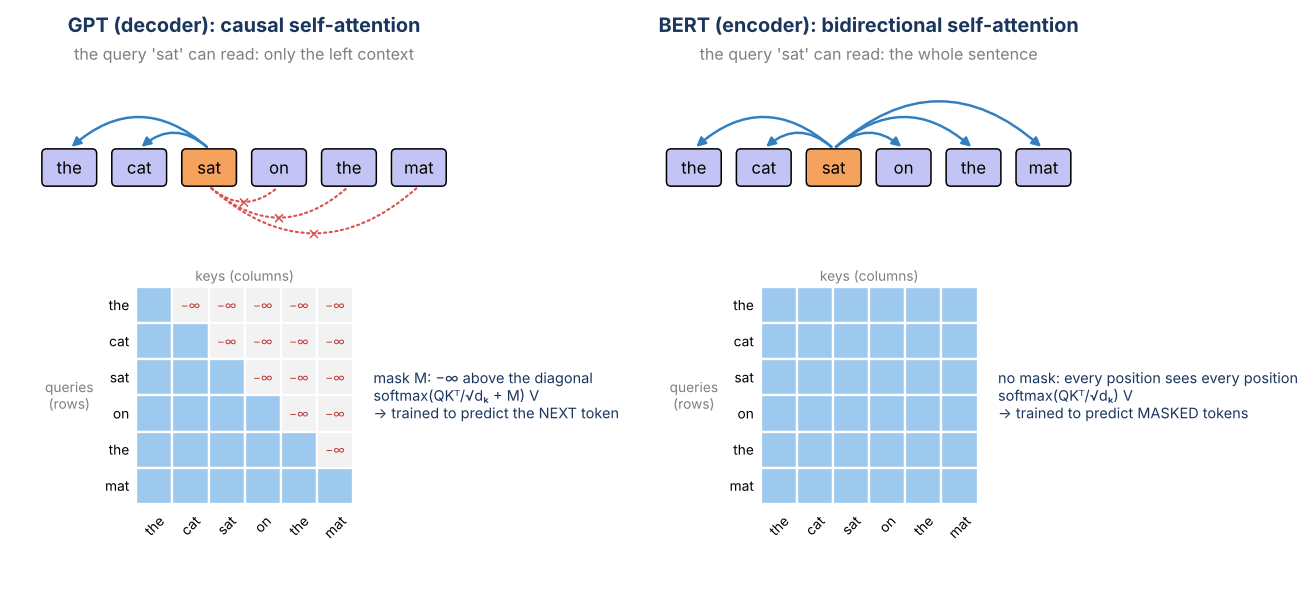

🤔 **Discuss.** Why can't we pretrain BERT like GPT, by predicting the next token? (Remember the _"no causal mask (cheating!)"_ ablation of Exercise 2 in the GPT lab: what happened to its training loss, and to its generated text?)


### 🧩 BERT in one picture

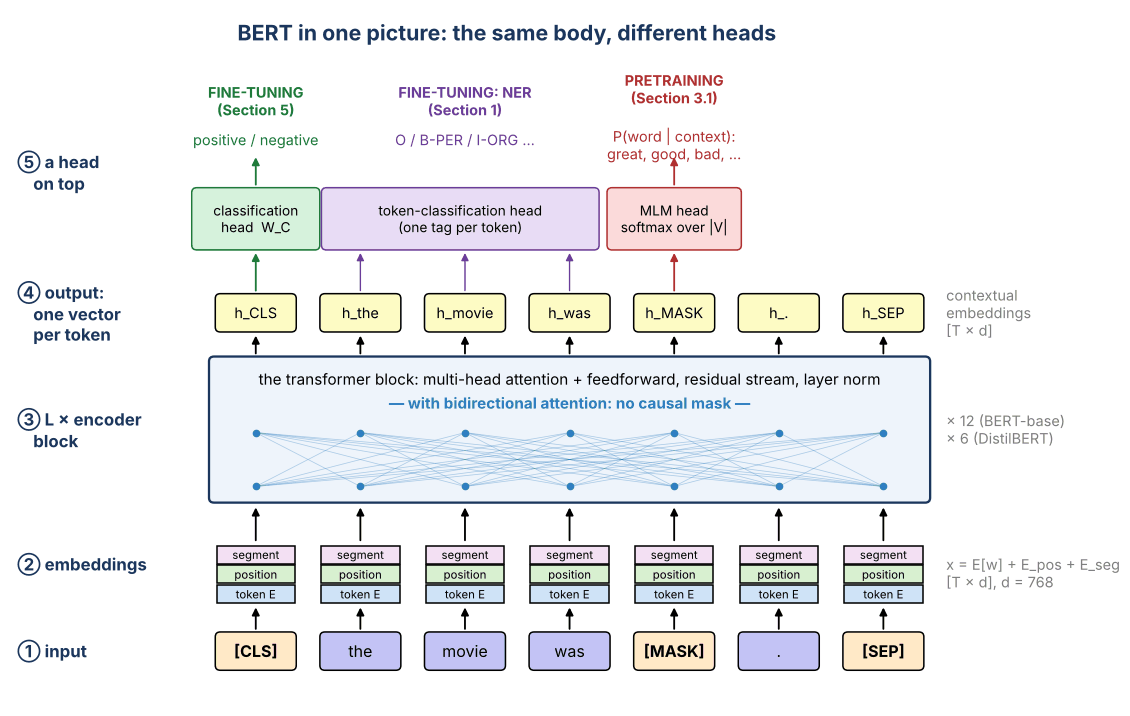

1. **Input.** The tokenizer adds two special tokens (Section 2): `[CLS]` at the start and `[SEP]` at the end of every sequence. During pretraining, some tokens are replaced by `[MASK]`.
2. **Embeddings.** Each token becomes a vector of size $d$: the **token** embedding (a row of $E$) + a learned **position** embedding (512 of them: hence the 512-token limit of Section 5) + a **segment** embedding (sentence A or B, for inputs made of two sentences).
3. **Encoder blocks.** $L$ transformer blocks with bidirectional attention. Input and output have the same shape $[T \times d]$, so the blocks can be stacked (12 in BERT-base, 6 in DistilBERT).
4. **Output.** One vector per token: a **contextual embedding**. Unlike the static embeddings of the word embeddings lab (one vector per word), the vector of a token depends on the whole sentence: Section 3.2 shows it with _bank_.
5. **A head on top**, which depends on what we want:
   - **pretraining**: the **MLM head** (an unembedding and a softmax over the vocabulary, like GPT's language modeling head) predicts the tokens that were masked;
   - **fine-tuning**: the MLM head is replaced by a small task head, trained on labelled data together with the encoder: a linear layer on the `[CLS]` vector for **classification** (SLP Eq. 9.6, the sentiment model of Section 5), or a linear layer on every token for **tagging** (the NER model of Section 1).

|             | GPT (decoder)                     | BERT (encoder)                                         |
| ----------- | --------------------------------- | ------------------------------------------------------ |
| attention   | causal: left context only         | bidirectional: the whole input                         |
| pretraining | predict the next token            | predict the masked tokens (MLM)                        |
| what we use | the last position: the next token | every position: contextual embeddings                  |
| good at     | generating text                   | understanding text: classification, tagging, retrieval |
| examples    | GPT-2, Llama, Qwen                | BERT, RoBERTa, DistilBERT, DeBERTa, ModernBERT         |


### 🙈 Pretraining an encoder: masked language modeling

BERT is pretrained on unlabelled text by hiding some tokens and asking the model to predict them **from both sides**: _the cat sat on the_ `[MASK]` _._ → _mat_. The loss is the usual cross-entropy, computed **only on the hidden positions**; everything else is the same as pretraining a GPT.

> 🔍 **The masking recipe (SLP §9.3.1).** 15% of the tokens are selected; of these, 80% are replaced by `[MASK]`, 10% by a random token, 10% are left unchanged. (Why not always `[MASK]`? Because `[MASK]` never appears after pretraining: the random and unchanged tokens force the model to build a good contextual vector at _every_ position, not only at the masked ones.) The loss is computed **only on the selected positions**. Hugging Face implements this in `DataCollatorForLanguageModeling`: let us look at one masked batch. The positions that do not contribute to the loss get the label **-100**, the value that PyTorch's `cross_entropy` ignores.


In [ ]:
from transformers import DataCollatorForLanguageModeling

collator = DataCollatorForLanguageModeling(tokenizer, mlm_probability=0.15)
sentence = "the movie was long but i loved every minute of it , the acting was superb and the music was moving"
torch.manual_seed(3)
mlm_batch = collator([tokenizer(sentence)])

rows = []
for orig, inp, lab in zip(
    tokenizer(sentence)["input_ids"], mlm_batch["input_ids"][0], mlm_batch["labels"][0]
):
    rows.append({
        "original": tokenizer.convert_ids_to_tokens(orig),
        "model input": tokenizer.convert_ids_to_tokens(int(inp)),
        "label": "-100 (ignored)"
        if lab == -100
        else tokenizer.convert_ids_to_tokens(int(lab)),
    })
pd.DataFrame(rows).T

,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
original,[CLS],the,movie,was,long,but,i,loved,every,minute,...,the,acting,was,superb,and,the,music,was,moving,[SEP]
model input,[CLS],[MASK],movie,[MASK],long,[MASK],i,loved,every,minute,...,the,[MASK],was,superb,and,the,music,was,moving,[SEP]
label,-100 (ignored),the,-100 (ignored),was,-100 (ignored),but,-100 (ignored),-100 (ignored),-100 (ignored),-100 (ignored),...,-100 (ignored),acting,-100 (ignored),-100 (ignored),-100 (ignored),-100 (ignored),-100 (ignored),-100 (ignored),-100 (ignored),-100 (ignored)


Run the cell again with another seed: different positions are selected each time. This is **dynamic masking** (RoBERTa): the same sentence gives a new training example at every epoch.

## 🔍 3.1 Fill-mask by hand

`AutoModelForMaskedLM` is BERT with its **MLM head**: for every position, a distribution over the 30,522 tokens of the vocabulary (SLP Eq. 9.3–9.4). The pipeline of Section 1 just looks at the row of the `[MASK]` position.


In [ ]:
from transformers import AutoModelForMaskedLM

mlm = (
    AutoModelForMaskedLM
    .from_pretrained("google-bert/bert-base-uncased")
    .to(DEVICE)
    .eval()
)

text = "the cat sat on the [MASK] ."
inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    logits = mlm(**inputs).logits  # [1, T, |V|]: one distribution per position
mask_pos = (inputs["input_ids"][0] == tokenizer.mask_token_id).nonzero().item()
probs = F.softmax(logits[0, mask_pos], dim=-1)
top = torch.topk(probs, 8)
print("logits shape:", tuple(logits.shape))
pd.DataFrame({
    "token": tokenizer.convert_ids_to_tokens(top.indices.tolist()),
    "P": top.values.tolist(),
}).round(3)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: google-bert/bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


logits shape: (1, 9, 30522)


,token,P
0,floor,0.314
1,bed,0.119
2,couch,0.107
3,sofa,0.060
4,ground,0.055
5,rug,0.019
6,table,0.018
7,porch,0.016


### 🧬 Anatomy of a checkpoint

A model is a `torch.nn.Module` like the tiny GPT of the GPT lab: the same blocks, just bigger. The configuration tells you the sizes of Lecture 14.


In [ ]:
cfg = mlm.config
print(
    f"layers L = {cfg.num_hidden_layers}, model dimension d = {cfg.hidden_size}, heads A = {cfg.num_attention_heads}, "
    f"d_ff = {cfg.intermediate_size}, max positions N = {cfg.max_position_embeddings}, |V| = {cfg.vocab_size}"
)
print(f"parameters: {mlm.num_parameters():,}")
print(
    mlm.bert.encoder.layer[0]
)  # one transformer block: attention (Q, K, V, output) + feedforward + 2 layer norms

layers L = 12, model dimension d = 768, heads A = 12, d_ff = 3072, max positions N = 512, |V| = 30522
parameters: 109,514,298
BertLayer(
  (attention): BertAttention(
    (self): BertSelfAttention(
      (query): Linear(in_features=768, out_features=768, bias=True)
      (key): Linear(in_features=768, out_features=768, bias=True)
      (value): Linear(in_features=768, out_features=768, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (output): BertSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (intermediate): BertIntermediate(
    (dense): Linear(in_features=768, out_features=3072, bias=True)
    (intermediate_act_fn): GELUActivation()
  )
  (output): BertOutput(
    (dense): Linear(in_features=3072, out_features=768, bias=True)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (d

> 🔍 **Postnorm.** Look at the block: BERT applies `LayerNorm` _after_ each residual addition (_postnorm_, the original transformer), while GPT-2, our tiny GPT and most modern LLMs normalize _before_ (_prenorm_, the variant you saw in Lecture 14). And the activation is GELU, as in our tiny GPT.

## 🏦 3.2 Contextual embeddings: the bank strikes back

The word embeddings lab ended with a defeat: a static embedding has **one** vector for _bank_, a blend of all its senses. In a transformer the vector of a token is **recomputed in context** at every layer (SLP §9.6, _contextual embeddings_). Let us extract the vector of _bank_ from every layer of BERT, in sentences with the two senses.

> 🎲 **Bet:** at the input layer (layer 0, the token embedding + position), how similar are the four _bank_ vectors? And at the last layer?


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


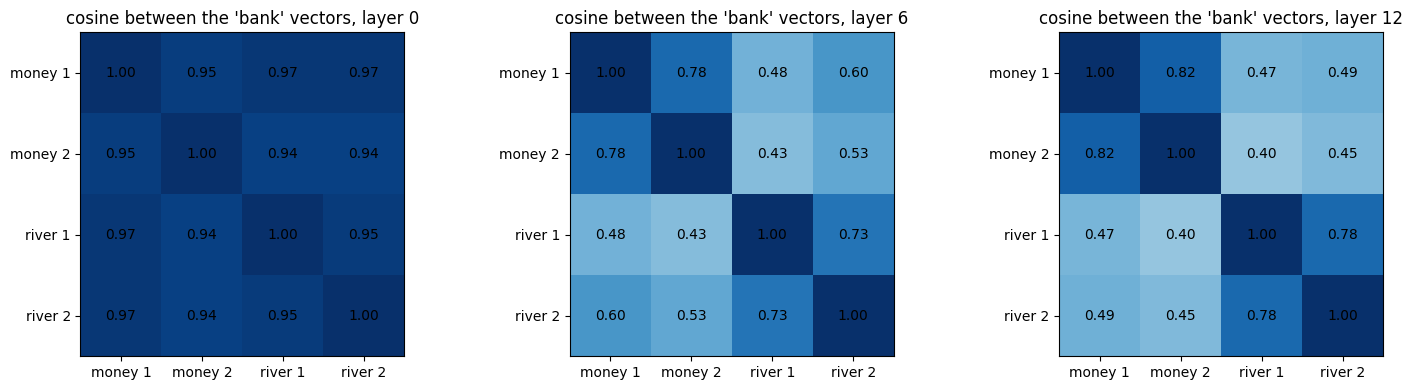

In [ ]:
from transformers import AutoModel

bert = (
    AutoModel.from_pretrained("google-bert/bert-base-uncased").to(DEVICE).eval()
)  # no head: just the encoder

bank_sentences = [
    "i deposited the money at the bank this morning .",  # money
    "the bank approved my loan last week .",  # money
    "we had a picnic on the grassy bank of the river .",  # river
    "the fisherman sat on the bank and watched the water .",  # river
]


@torch.no_grad()
def word_vectors(sentences, word, model=bert):
    # Output: tensor [n_layers + 1, n_sentences, d]: the vector of `word` at every layer, in every sentence
    out = []
    for s in sentences:
        enc = tokenizer(s, return_tensors="pt").to(DEVICE)
        pos = tokenizer.convert_ids_to_tokens(enc["input_ids"][0]).index(
            word
        )  # position of the word
        hidden = model(
            **enc, output_hidden_states=True
        ).hidden_states  # tuple of L+1 tensors [1, T, d]
        out.append(torch.stack([h[0, pos] for h in hidden]))
    return torch.stack(out, dim=1).cpu()


def cos_matrix(V):
    V = F.normalize(V, dim=-1)
    return (V @ V.T).numpy()


vecs = word_vectors(bank_sentences, "bank")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, layer in zip(axes, [0, 6, 12]):
    ax.imshow(cos_matrix(vecs[layer]), vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(4))
    ax.set_xticklabels(["money 1", "money 2", "river 1", "river 2"])
    ax.set_yticks(range(4))
    ax.set_yticklabels(["money 1", "money 2", "river 1", "river 2"])
    for i in range(4):
        for j in range(4):
            ax.text(
                j, i, f"{cos_matrix(vecs[layer])[i, j]:.2f}", ha="center", va="center"
            )
    ax.set_title(f"cosine between the 'bank' vectors, layer {layer}")
plt.tight_layout()
plt.show()

Layer by layer: the average cosine between two _bank_ vectors with the **same** sense, and with **different** senses.


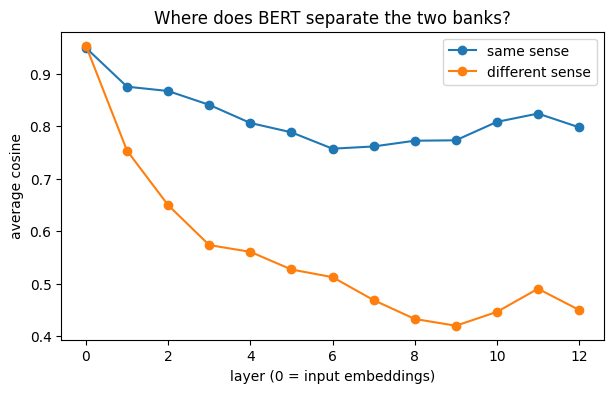

In [ ]:
same, diff = [], []
for layer in range(vecs.shape[0]):
    C = cos_matrix(vecs[layer])
    same.append((C[0, 1] + C[2, 3]) / 2)
    diff.append(C[:2, 2:].mean())
plt.figure(figsize=(7, 4))
plt.plot(same, marker="o", label="same sense")
plt.plot(diff, marker="o", label="different sense")
plt.xlabel("layer (0 = input embeddings)")
plt.ylabel("average cosine")
plt.title("Where does BERT separate the two banks?")
plt.legend()
plt.show()

🤔 **Discuss.**

- Why are the four vectors (almost) identical at layer 0? What is still different between them?
- The cosines between _different_ senses stay quite high (well above 0) even in the last layers. Is BERT confused, or is something else going on? (Hint: compute the cosine between _bank_ and a random word, e.g. _the_, in the last layer.)
- How would you build a **word sense** classifier from these vectors with a handful of labelled examples?


## 👀 3.3 A peek at the attention weights

With `output_attentions=True` the model also returns the weights $\alpha_{ij}$ of every head: a tensor `[batch, heads, T, T]` per layer, the same objects as in Exercise 1 of the GPT lab, but now **bidirectional** (no triangle). The classic example is a pronoun: who is _it_?

> ⚙️ Fast attention kernels (SDPA, FlashAttention) never build the matrix of weights. To get it back we load the model with `attn_implementation="eager"`, the plain implementation of Lecture 14.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


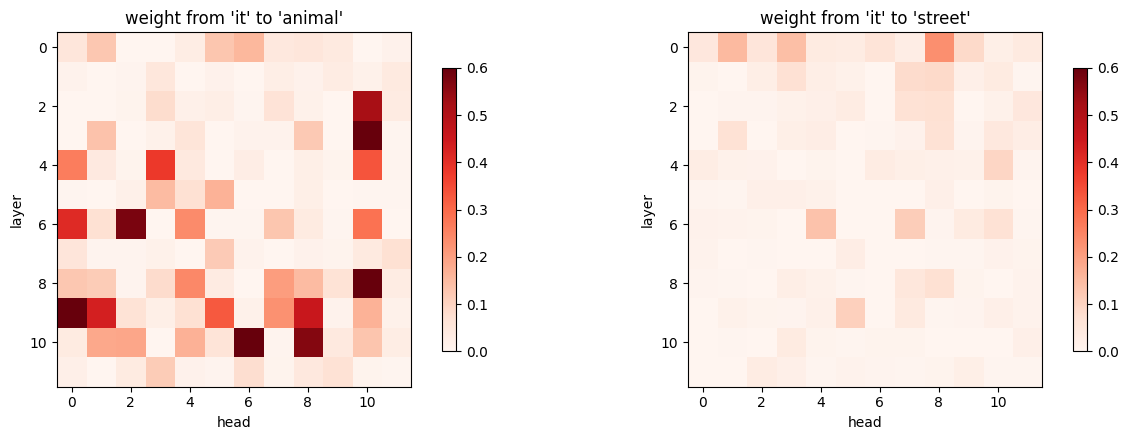

strongest it -> animal head: layer 3, head 10


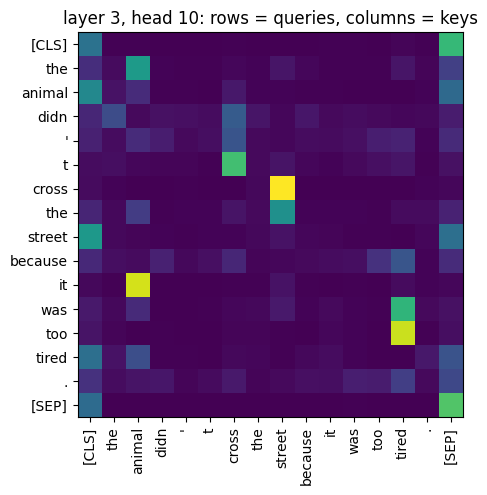

In [ ]:
bert_att = (
    AutoModel
    .from_pretrained("google-bert/bert-base-uncased", attn_implementation="eager")
    .to(DEVICE)
    .eval()
)

sentence = "the animal didn't cross the street because it was too tired ."
enc = tokenizer(sentence, return_tensors="pt").to(DEVICE)
toks = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
with torch.no_grad():
    att = torch.stack(bert_att(**enc, output_attentions=True).attentions)[
        :, 0
    ].cpu()  # [L, A, T, T]

i_it, i_animal, i_street = toks.index("it"), toks.index("animal"), toks.index("street")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, j, name in [(axes[0], i_animal, "animal"), (axes[1], i_street, "street")]:
    im = ax.imshow(att[:, :, i_it, j].numpy(), cmap="Reds", vmin=0, vmax=0.6)
    ax.set_xlabel("head")
    ax.set_ylabel("layer")
    ax.set_title(f"weight from 'it' to '{name}'")
    plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

l, a = np.unravel_index(att[:, :, i_it, i_animal].argmax().item(), att.shape[:2])
print(f"strongest it -> animal head: layer {l}, head {a}")
plt.figure(figsize=(6, 5))
plt.imshow(att[l, a].numpy(), cmap="viridis")
plt.xticks(range(len(toks)), toks, rotation=90)
plt.yticks(range(len(toks)), toks)
plt.title(f"layer {l}, head {a}: rows = queries, columns = keys")
plt.show()

🤔 **Discuss.** Change _tired_ into _wide_: now _it_ is the street. Do the same heads follow? Many heads put most of their weight on `[SEP]` or `[CLS]`: what could such a head be doing? Is a high attention weight an **explanation** of the prediction?


# ✍️ 4. Decoders: next-token prediction, generation and chat

The tiny GPT of the GPT lab, at full scale. `AutoModelForCausalLM` is a decoder with its **language modeling head** (SLP §7.5): for every position, logits over the vocabulary for the **next** token.

## 🎰 4.1 The same casino, 50,257 slots

> 🎲 **Bet:** after _"The capital of Italy is"_, which token does GPT-2 (2019, 124M parameters) bet on, and with which probability?


In [ ]:
from transformers import AutoModelForCausalLM

gpt2_tok = AutoTokenizer.from_pretrained("openai-community/gpt2")
gpt2 = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(DEVICE).eval()

prompt = "The capital of Italy is"
inputs = gpt2_tok(prompt, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    logits = gpt2(**inputs).logits  # [1, T, 50257]
probs = F.softmax(logits[0, -1], dim=-1)  # the LAST position predicts the next token
top = torch.topk(probs, 10)
pd.DataFrame({
    "next token": [repr(gpt2_tok.decode(i)) for i in top.indices.tolist()],
    "P": top.values.tolist(),
}).round(3)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

,next token,P
0,' Rome',0.157
1,' the',0.073
2,' Milan',0.047
3,' a',0.034
4,' now',0.032
5,' in',0.023
6,' also',0.023
7,' home',0.019
8,' not',0.016
9,' Italy',0.016


## 🎛️ 4.2 Decoding with `generate`

`generate` runs the autoregressive loop of the GPT lab for us (with the KV cache of SLP §7.8 already implemented). The decoding policy is a set of arguments (SLP §7.6):

| argument                        | meaning                                                                       |
| ------------------------------- | ----------------------------------------------------------------------------- |
| `max_new_tokens`                | how many tokens to generate                                                   |
| `do_sample=False`               | **greedy** decoding: always the most probable token                           |
| `do_sample=True, temperature=τ` | sample from softmax(logits / τ)                                               |
| `top_k=k`                       | sample only among the $k$ most probable tokens                                |
| `top_p=p`                       | **nucleus** sampling: the smallest set of tokens with total probability ≥ $p$ |
| `repetition_penalty`            | lower the logits of tokens already generated                                  |


In [ ]:
def complete(prompt, model=gpt2, tok=gpt2_tok, seed=0, **gen_kwargs):
    # generate a continuation of `prompt` and return only the new text
    transformers.set_seed(seed)
    inputs = tok(prompt, return_tensors="pt").to(DEVICE)
    out = model.generate(**inputs, pad_token_id=tok.eos_token_id, **gen_kwargs)
    return tok.decode(out[0, inputs["input_ids"].shape[1] :], skip_special_tokens=True)


prompt = "In this course on natural language processing, we will learn how to"
print("GREEDY:\n", complete(prompt, max_new_tokens=50, do_sample=False))
print(
    "\nSAMPLING, temperature 1.0:\n",
    complete(prompt, max_new_tokens=50, do_sample=True, temperature=1.0, top_k=0),
)
print(
    "\nTOP-P 0.9, temperature 0.7:\n",
    complete(
        prompt, max_new_tokens=50, do_sample=True, temperature=0.7, top_p=0.9, top_k=0
    ),
)

GREEDY:
  use the language to solve problems in real-world situations. We will also learn how to use the language to solve problems in real-world situations. We will also learn how to use the language to solve problems in real-world situations. We will

SAMPLING, temperature 1.0:
  develop sophisticated logic competitions, imagining results similar to poker, with concurrent finite embedded deep learning (CLD) algorithms helping to create a class that lists large numbers of competing Billions.

Coursework will be given in multiple repetition rates, from 30

TOP-P 0.9, temperature 0.7:
  develop a set of mathematical models that can be used in software to create real-world applications. We will also explore how to use the text-based mathematical models to help human-computer interactions. We will develop a set of application programming languages, including


🤔 **Discuss.** Greedy decoding loops, like the greedy bigram of the GPT lab. Why does a model with a 1024-token context still get stuck in a loop? Try `repetition_penalty=1.3` with greedy decoding.


## 💬 4.3 From a language model to an assistant: chat templates

GPT-2 is a **base** model: it continues text (the _internet-document simulator_ of Lecture 20). Ask it a question and it may continue with more questions. Chat assistants are base models that went through **post-training** (SLP Ch. 8, Lectures 18–20): **instruction tuning** (supervised fine-tuning on instruction/response pairs, §8.1) and preference alignment (§8.3–8.4).

We use **Qwen2.5-0.5B-Instruct**, a small (0.5 billion parameters) instruction-tuned model that fits on a laptop. To an instruction-tuned model, a conversation is a list of messages with **roles**:


In [ ]:
chat_name = "Qwen/Qwen2.5-0.5B-Instruct"
chat_tok = AutoTokenizer.from_pretrained(chat_name)
chat_model = (
    AutoModelForCausalLM
    .from_pretrained(chat_name, dtype=torch.float16 if ON_GPU else torch.float32)
    .to(DEVICE)
    .eval()
)

messages = [
    {
        "role": "system",
        "content": "You are a concise teaching assistant for a university NLP course.",
    },
    {
        "role": "user",
        "content": "In one sentence: what is the difference between BERT and GPT?",
    },
]
chat_text = chat_tok.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True
)
print(chat_text)

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

<|im_start|>system
You are a concise teaching assistant for a university NLP course.<|im_end|>
<|im_start|>user
In one sentence: what is the difference between BERT and GPT?<|im_end|>
<|im_start|>assistant



The **chat template** turns the list of messages into **one string**, with special tokens (`<|im_start|>`, `<|im_end|>`) that mark who is speaking. `add_generation_prompt=True` appends the header of the assistant's turn, so that the most probable continuation is... the assistant's answer. There is no magic: a chat model is still a next-token predictor, trained on text formatted this way (_a conversation is just tokens_, Lecture 20). Every model family has its own template: always use `apply_chat_template` instead of writing the format by hand.


In [ ]:
def chat(messages, max_new_tokens=120, **gen_kwargs):
    # apply the chat template, generate, and return only the assistant's answer
    text = chat_tok.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = chat_tok(text, return_tensors="pt").to(DEVICE)
    out = chat_model.generate(
        **inputs, max_new_tokens=max_new_tokens, do_sample=False, **gen_kwargs
    )
    return chat_tok.decode(
        out[0, inputs["input_ids"].shape[1] :], skip_special_tokens=True
    )


question = "What is the capital of Italy? Answer with one word."
print("INSTRUCT MODEL:", chat([{"role": "user", "content": question}]))
print("\nBASE GPT-2:     ", complete(question, max_new_tokens=30, do_sample=False))

INSTRUCT MODEL: Florence

BASE GPT-2:      

Italy is the capital of Italy.

Italy is the capital of Italy.

Italy is the capital of Italy.

Italy


🤔 **Discuss.** Is the instruct model's answer correct? Compare with the probability that GPT-2 gave to _Rome_ in Section 4.1. What did post-training teach the model, and what did it not teach? (Think of the _hallucinations_ of Lecture 20.)


### 🧑‍🏫 What instruction-tuning data looks like

Supervised fine-tuning (SLP §8.1, Lecture 20) uses the same next-token cross-entropy as pretraining, but **only the response tokens** count: the prompt is context, not a target. In Hugging Face this is implemented exactly like the MLM masking above: the labels of the prompt tokens are set to **-100**.


In [ ]:
example = [
    {
        "role": "user",
        "content": "Is this review positive or negative? 'A total waste of time.'",
    },
    {"role": "assistant", "content": "negative"},
]
prompt_ids = chat_tok(
    chat_tok.apply_chat_template(
        example[:1], tokenize=False, add_generation_prompt=True
    )
)["input_ids"]
full_ids = chat_tok(chat_tok.apply_chat_template(example, tokenize=False))["input_ids"]
labels = [-100] * len(prompt_ids) + full_ids[
    len(prompt_ids) :
]  # loss only on the answer (and its end token)

print(
    pd.DataFrame({
        "token": [repr(chat_tok.decode(i)) for i in full_ids],
        "label": ["-100" if l == -100 else repr(chat_tok.decode(l)) for l in labels],
    }).T.to_string()
)

                   0         1     2      3       4     5      6     7           8      9           10        11    12      13      14    15          16            17    18            19    20              21      22    23    24       25         26           27     28           29    30    31    32        33        34     35       36    37            38    39              40           41    42          43            44    45
token  '<|im_start|>'  'system'  '\n'  'You'  ' are'  ' Q'  'wen'   ','  ' created'  ' by'  ' Alibaba'  ' Cloud'   '.'  ' You'  ' are'  ' a'  ' helpful'  ' assistant'   '.'  '<|im_end|>'  '\n'  '<|im_start|>'  'user'  '\n'  'Is'  ' this'  ' review'  ' positive'  ' or'  ' negative'   '?'  " '"   'A'  ' total'  ' waste'  ' of'  ' time'  ".'"  '<|im_end|>'  '\n'  '<|im_start|>'  'assistant'  '\n'  'negative'  '<|im_end|>'  '\n'
label            -100      -100  -100   -100    -100  -100   -100  -100        -100   -100        -100      -100  -100    -100    -100  -100  

> 🔍 **Encoder or decoder for your project?** Rule of thumb: for **classification and tagging** with a few thousand labelled examples, a fine-tuned **encoder** (BERT, RoBERTa, DeBERTa, ModernBERT) is cheap, fast and a strong default, but always compare it with an LLM baseline: the gap can surprise you. For **generation** (answers, summaries, translations) and for tasks with **no training data**, use a **decoder** (an instruction-tuned LLM) with a good prompt, and fine-tune it with LoRA (Section 5.13) if you have data.

> 🔍 **And encoder-decoder models?** T5, BART and MarianMT (translation) have their own Auto class, `AutoModelForSeq2SeqLM`, and are used with the same `generate`: the encoder reads the source, the decoder writes the target, attending to the encoder through cross-attention.


# 🎬 5. A mini-project: fine-tune DistilBERT on our movie reviews

Time to train. We treat this as a small "real project", with a checklist you could follow in your group project:

|     | step                                             | in this notebook                                                     |
| --- | ------------------------------------------------ | -------------------------------------------------------------------- |
| 1   | define the task and the **metric**               | binary sentiment, accuracy (balanced classes) + F1                   |
| 2   | get the data, look at it, fix the **splits**     | train / validation / test, test touched only once                    |
| 3   | build **baselines** first                        | majority class, TF-IDF + logistic regression, an off-the-shelf model |
| 4   | make the **preprocessing** choices               | tokenizer, maximum length, truncation                                |
| 5   | choose a pretrained model and a **head**         | DistilBERT + a classification head                                   |
| 6   | train, watching the **validation** set           | `Trainer`, learning curves, best checkpoint                          |
| 7   | evaluate **once** on test                        | accuracy, P/R/F1, confusion matrix; what fine-tuning buys            |
| 8   | look at the **errors**, and fix what they reveal | the most confident mistakes; head + tail truncation                  |
| 9   | is the difference **significant**?               | paired bootstrap (Lecture 07)                                        |
| 10  | **save** and share                               | `save_pretrained`, `pipeline`, the Hub                               |

## 📦 5.1 The data and the splits

The `movie_reviews` corpus of NLTK (Pang & Lee): 1,000 positive and 1,000 negative reviews, lowercased and tokenized. We rebuild **exactly** the split of the NLTK lab (`random_state=0`, 20% test), so that the numbers are comparable with that scoreboard. Then we carve a **validation set** out of the training set: it is the set we look at while training and choosing hyperparameters, so that the test set stays untouched until the very end.

The `datasets` library stores the data in a `Dataset` (a table backed by Apache Arrow, memory-mapped from disk) and a split collection in a `DatasetDict`.


In [ ]:
# Free the memory of the Part I models we do not need anymore (we keep the SST-2 `classifier` and the chat model)
import gc

for name in ["mlm", "bert", "bert_att", "gpt2", "unmasker", "ner", "model_sst2"]:
    globals().pop(name, None)
gc.collect()
if ON_GPU:
    torch.cuda.empty_cache()
    print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

GPU memory in use: 2.2 GB


In [ ]:
from datasets import Dataset, DatasetDict
from nltk.corpus import movie_reviews
from sklearn.model_selection import train_test_split

mr_ids = movie_reviews.fileids()
mr_text = [movie_reviews.raw(f) for f in mr_ids]
mr_y = np.array([1 if f.startswith("pos") else 0 for f in mr_ids])

# The split of the NLTK lab: 1600 train / 400 test, stratified, random_state=0
idx_trainval, idx_test = train_test_split(
    np.arange(len(mr_ids)), test_size=0.2, random_state=0, stratify=mr_y
)
# NEW: 200 of the 1600 training reviews become the validation set
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=200, random_state=0, stratify=mr_y[idx_trainval]
)


def make_split(idx):
    return Dataset.from_dict({
        "text": [mr_text[i] for i in idx],
        "label": mr_y[idx].tolist(),
    })


reviews = DatasetDict(
    train=make_split(idx_train),
    validation=make_split(idx_val),
    test=make_split(idx_test),
)
y_test = mr_y[idx_test]
reviews

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 1400
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 200
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 400
    })
})

> 🔍 **Columns are lazy.** `reviews["train"][0]` is one example (a dict); `reviews["train"]["text"]` is a whole **column**, which recent versions of `datasets` return as a lazy `Column` object, not a Python list. Wrap it in `list(...)` before passing it to a tokenizer, to scikit-learn or to a pipeline, as we do below.


In [22]:
example = reviews["train"][0]
print("label:", example["label"], "(1 = positive)")
print(example["text"][:1200], "...")

label: 0 (1 = positive)
there's a good , and timely , story trapped deep within the excess of murder in the first , a new movie about the abuses of our prison system . 
with a country wrapped up in feverish debate over the crime issue and the rights of the accused and the incarcerated in jeopardy , this expose would offer something rare to recent american movies--a point of view . 
but director marc rocco makes it clear from the beginning that pretentious , often nauseating , camera movements and slick , mtv- style lighting and editing are far more important . 
there's not a moment in the picture where he surrenders technique for pure storytelling . 
and everything suffers . 
christian slater and kevin bacon star as defense attorney and alcatraz inmate , respectively . 
after spending an unprecedented amount of time in an isolated cell for attempting to escape , bacon murders another prisoner and faces trial . 
his young lawyer ( slater ) is fresh out of law school but determined to " 

## 📏 5.2 How long is a review, in tokens?

BERT-like models have a **maximum input length** (512 tokens for BERT and DistilBERT: the size of the position embedding matrix $E_{pos}$). Before training, measure your data.

> 🎲 **Bet:** what fraction of the reviews is longer than 512 tokens?


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1176 > 512). Running this sequence through the model will result in indexing errors


tokens per review: median 794, mean 847, max 3253
longer than 512 tokens: 84.6%


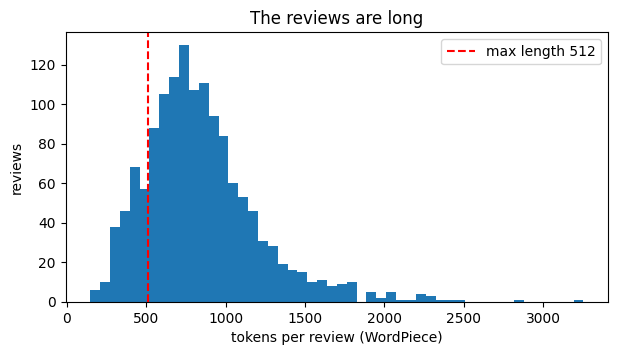

In [ ]:
CHECKPOINT = "distilbert/distilbert-base-uncased"  # 66M parameters, 6 layers: a distilled (smaller, faster) BERT
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)

n_tokens = np.array([
    len(ids) for ids in tokenizer(list(reviews["train"]["text"]))["input_ids"]
])
print(
    f"tokens per review: median {np.median(n_tokens):.0f}, mean {n_tokens.mean():.0f}, max {n_tokens.max()}"
)
print(f"longer than 512 tokens: {np.mean(n_tokens > 512):.1%}")

plt.figure(figsize=(7, 3.5))
plt.hist(n_tokens, bins=50)
plt.axvline(512, color="red", linestyle="--", label="max length 512")
plt.xlabel("tokens per review (WordPiece)")
plt.ylabel("reviews")
plt.legend()
plt.title("The reviews are long")
plt.show()

## 🥉 5.3 Baselines first

A number means nothing without a baseline. Before spending GPU time, we compute three:

1. **majority class**: always predict the most frequent class (here 50%);
2. **TF-IDF + logistic regression**, the recipe of the word embeddings lab (unigrams and bigrams, sublinear tf), trained on our training set: the _strong classic baseline_;
3. **DistilBERT SST-2** with no training on these reviews (the bonus model of the NLTK lab): a pretrained transformer, but fine-tuned on _another_ dataset.

We keep all the test accuracies in a `LEADERBOARD`, and all the test predictions in `PREDICTIONS` (we need them for the significance test). Note that TF-IDF and logistic regression are fitted on the **training** split only (1,400 reviews): the validation reviews are kept apart for every model.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    precision_recall_fscore_support,
)

LEADERBOARD, PREDICTIONS = {}, {}


def record(name, pred):
    # store the test predictions of a system and print its accuracy and macro-F1
    pred = np.asarray(pred)
    PREDICTIONS[name] = pred
    LEADERBOARD[name] = accuracy_score(y_test, pred)
    f1 = precision_recall_fscore_support(
        y_test, pred, average="macro", zero_division=0
    )[2]
    print(f"{name:45s} accuracy {LEADERBOARD[name]:.4f}   macro-F1 {f1:.4f}")


def show_leaderboard():
    display(
        pd
        .Series(LEADERBOARD, name="test accuracy")
        .sort_values(ascending=False)
        .round(4)
        .to_frame()
    )


# 1. majority class
majority = Counter(list(reviews["train"]["label"])).most_common(1)[0][0]
record("majority class", np.full(len(y_test), majority))

# 2. TF-IDF + logistic regression (L12 recipe)
tfidf = TfidfVectorizer(
    ngram_range=(1, 2), min_df=2, max_features=12000, sublinear_tf=True
)
X_train_tfidf = tfidf.fit_transform(list(reviews["train"]["text"]))
clf_tfidf = LogisticRegression(max_iter=2000, random_state=SEED).fit(
    X_train_tfidf, list(reviews["train"]["label"])
)
record("TF-IDF + LR", clf_tfidf.predict(tfidf.transform(list(reviews["test"]["text"]))))

majority class                                accuracy 0.5000   macro-F1 0.3333
TF-IDF + LR                                   accuracy 0.8600   macro-F1 0.8600


In [ ]:
# 3. DistilBERT fine-tuned on SST-2, no training on our reviews (≈ 30 s on GPU, a few minutes on CPU)
RUN_SST2 = True
if RUN_SST2:
    out = classifier(list(reviews["test"]["text"]), batch_size=32, truncation=True)
    record(
        "DistilBERT fine-tuned on SST-2 (not on our reviews)",
        [int(o["label"] == "POSITIVE") for o in out],
    )
show_leaderboard()

DistilBERT fine-tuned on SST-2 (not on our reviews) accuracy 0.8525   macro-F1 0.8516


,test accuracy
TF-IDF + LR,0.8600
DistilBERT fine-tuned on SST-2 (not on our reviews),0.8525
majority class,0.5000


## 🔢 5.4 Tokenize the whole dataset

`Dataset.map` applies a function to every example (with `batched=True`, to a batch of examples at a time, which is much faster with a fast tokenizer) and **adds** the returned columns to the dataset. The result is cached.

We **truncate** but we do **not pad** here: padding every review to 512 tokens wastes computation on short reviews. Instead, a **data collator** pads each mini-batch to the length of its longest sequence (_dynamic padding_).


In [ ]:
# Budget: the GPU budget reads 512 tokens; on CPU we read only 128 tokens to keep training time reasonable
MAX_LEN = 512 if ON_GPU else 128
EPOCHS = 3 if ON_GPU else 2
print(f"MAX_LEN = {MAX_LEN}, EPOCHS = {EPOCHS}")


def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)


tokenized = reviews.map(tokenize_batch, batched=True)
tokenized

MAX_LEN = 512, EPOCHS = 3


Map:   0%|          | 0/1400 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1400
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 200
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 400
    })
})

In [ ]:
from transformers import DataCollatorWithPadding

collate = DataCollatorWithPadding(tokenizer)
features = [
    {k: tokenized["train"][i][k] for k in ["input_ids", "attention_mask", "label"]}
    for i in range(4)
]
mini = collate(features)
print({
    k: tuple(v.shape) for k, v in mini.items()
})  # padded to the longest of these 4 reviews
print("lengths before padding:", [len(f["input_ids"]) for f in features])

{'input_ids': (4, 512), 'attention_mask': (4, 512), 'labels': (4,)}
lengths before padding: [428, 512, 512, 512]


## 🧠 5.5 The model: a pretrained body and a new head

`AutoModelForSequenceClassification` loads the pretrained encoder and adds a **classification head** on top of the `[CLS]` vector: $y = \mathrm{softmax}(h^L_{\mathrm{CLS}} W_C)$ (SLP Eq. 9.6). The encoder weights come from pretraining; the head is **new** and randomly initialized. The _load report_ printed by the next cell says exactly this: the head weights (`pre_classifier`, `classifier`) are **MISSING** from the checkpoint, so they are initialized at random, while the weights of the MLM head of the checkpoint (`vocab_transform`, `vocab_projector`, ...) are **UNEXPECTED**: our model has no use for them, and they are discarded. Fine-tuning trains the head _and_ updates the encoder (SLP §9.4.1).

`id2label`/`label2id` store the label names in the configuration, so that the saved model (and its `pipeline`) will speak _negative_/_positive_ instead of `LABEL_0`/`LABEL_1`.


In [ ]:
id2label = {0: "negative", 1: "positive"}
label2id = {v: k for k, v in id2label.items()}


def fresh_model(checkpoint=CHECKPOINT, seed=SEED):
    # a new copy of the pretrained encoder + a randomly initialized classification head
    transformers.set_seed(seed)  # the seed fixes the initialization of the head
    return AutoModelForSequenceClassification.from_pretrained(
        checkpoint, num_labels=2, id2label=id2label, label2id=label2id
    )


model = fresh_model()
print(f"parameters: {model.num_parameters():,}")
print("head:", model.pre_classifier, model.classifier, sep="\n")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


parameters: 66,955,010
head:
Linear(in_features=768, out_features=768, bias=True)
Linear(in_features=768, out_features=2, bias=True)


> 🎲 **Bet:** before any training, what loss do you expect on a batch? (The head is random, the classes are balanced. Remember the "fair baseline" of the GPT lab.)

When the batch contains a `labels` key, Hugging Face models compute the cross-entropy loss for you and return it in `output.loss`:


In [ ]:
mini_batch = collate(
    features
)  # the collator renames "label" -> "labels", the name the model expects
with torch.no_grad():
    output = model(**mini_batch)
print("logits:\n", output.logits)
print(f"loss: {output.loss.item():.4f}   ln 2 = {math.log(2):.4f}")

logits:
 tensor([[-0.0727, -0.0790],
        [-0.0253, -0.0239],
        [-0.0455, -0.0869],
        [-0.0478, -0.0851]])
loss: 0.6824   ln 2 = 0.6931


## 🏋️ 5.6 Training with `Trainer`

We could write the training loop ourselves, exactly as in the GPT lab (forward, loss, `backward`, `optimizer.step`). `Trainer` writes it for us, plus everything around it: batching with the collator, moving data to the GPU, mixed precision, the learning-rate schedule, evaluation, checkpoints, logging. Its configuration is a `TrainingArguments` object:

| argument                         | value     | why                                                                                                                   |
| -------------------------------- | --------- | --------------------------------------------------------------------------------------------------------------------- |
| `learning_rate`                  | 3e-5      | fine-tuning uses small learning rates (2e-5 – 5e-5): we only want to _adjust_ the pretrained weights                  |
| `num_train_epochs`               | 3 (GPU)   | a few passes are enough; more overfits a small dataset                                                                |
| `per_device_train_batch_size`    | 16        | limited by GPU memory: 16 × 512 tokens fits on a T4                                                                   |
| `warmup_steps`                   | 0.1       | a float < 1 is a fraction: the learning rate grows linearly for the first 10% of the steps, then decays linearly to 0 |
| `weight_decay`                   | 0.01      | AdamW's decoupled L2 regularization (Lecture 13)                                                                      |
| `eval_strategy`, `save_strategy` | `"epoch"` | evaluate on validation and save a checkpoint after every epoch                                                        |
| `load_best_model_at_end`         | `True`    | at the end, reload the checkpoint with the best validation accuracy                                                   |
| `fp16`                           | on GPU    | mixed precision: faster and lighter on a T4                                                                           |
| `report_to`                      | `"none"`  | no external logger (set `"wandb"` or `"tensorboard"` in a project)                                                    |

`compute_metrics` receives the logits and the labels of the evaluation set and returns a dictionary of metrics. `make_trainer` packs all this, because we will train several models (head + tail truncation, LoRA) with the same recipe.


In [ ]:
from transformers import Trainer, TrainingArguments


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    pred = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(
        labels, pred, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, pred),
        "precision": p,
        "recall": r,
        "f1": f1,
    }


def make_trainer(model, train_ds, eval_ds, output_dir, **overrides):
    # one place for the training recipe; overrides change single arguments (e.g. learning_rate=1e-4)
    args = {
        "output_dir": output_dir,
        # optim="adamw_torch", # the default HF optimiser
        # lr_scheduler_type="linear", # the default HF scheduler
        "learning_rate": 3e-5,
        "num_train_epochs": EPOCHS,
        "per_device_train_batch_size": 16,
        "per_device_eval_batch_size": 32,
        "warmup_steps": 0.1,
        "weight_decay": 0.01,
        "eval_strategy": "epoch",
        "save_strategy": "epoch",
        "save_total_limit": 1,  # keep only the best checkpoint on disk
        "load_best_model_at_end": True,
        "metric_for_best_model": "accuracy",
        "logging_steps": 10,
        "fp16": ON_GPU,
        "report_to": "none",
        "seed": SEED,
    }
    args.update(overrides)
    return Trainer(
        model=model,
        args=TrainingArguments(**args),
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics,
    )


trainer = make_trainer(
    model, tokenized["train"], tokenized["validation"], "runs/distilbert-full"
)
t0 = time.perf_counter()
trainer.train()
print(f"training time: {time.perf_counter() - t0:.0f} s")

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.552314,0.444311,0.800000,0.829670,0.800000,0.795396
2,0.245080,0.290790,0.870000,0.872383,0.870000,0.869792
3,0.167410,0.308566,0.900000,0.900641,0.900000,0.899960


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

training time: 86 s


## 📈 5.7 Learning curves

`trainer.state.log_history` is a list of dictionaries: the training loss every `logging_steps` steps, and the validation metrics after every epoch. Plot them: they are the first thing to look at when something goes wrong.


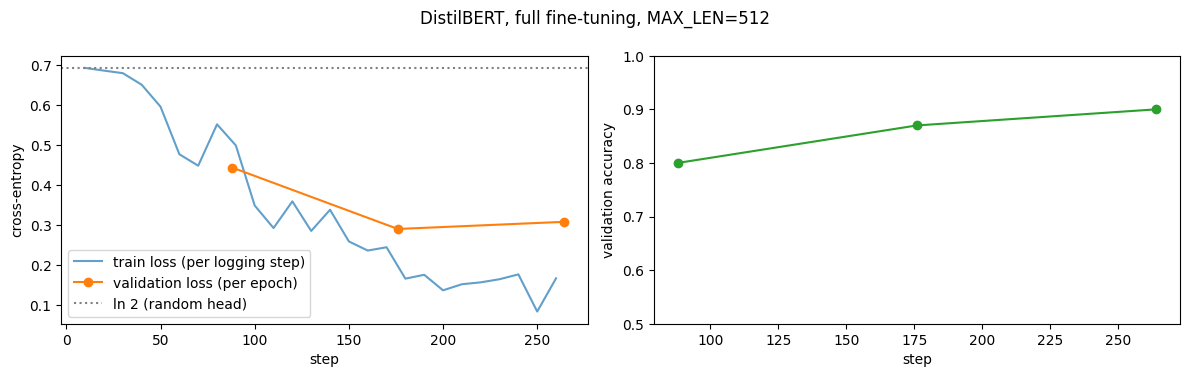

In [31]:
def plot_history(trainer, title=""):
    logs = trainer.state.log_history
    tr = [(l["step"], l["loss"]) for l in logs if "loss" in l and "eval_loss" not in l]
    ev = [
        (l["step"], l["eval_loss"], l["eval_accuracy"])
        for l in logs
        if "eval_loss" in l
    ]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot(*zip(*tr), label="train loss (per logging step)", alpha=0.7)
    axes[0].plot(
        [e[0] for e in ev],
        [e[1] for e in ev],
        marker="o",
        label="validation loss (per epoch)",
    )
    axes[0].axhline(
        math.log(2), color="gray", linestyle=":", label="ln 2 (random head)"
    )
    axes[0].set_xlabel("step")
    axes[0].set_ylabel("cross-entropy")
    axes[0].legend()
    axes[1].plot([e[0] for e in ev], [e[2] for e in ev], marker="o", color="C2")
    axes[1].set_xlabel("step")
    axes[1].set_ylabel("validation accuracy")
    axes[1].set_ylim(0.5, 1)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(trainer, f"DistilBERT, full fine-tuning, MAX_LEN={MAX_LEN}")

🤔 **Discuss.** Does the validation loss keep decreasing until the end? If the validation loss goes **up** in the last epoch while the validation accuracy stays flat or improves, is the model overfitting? Which checkpoint does `load_best_model_at_end` keep?


## 🧪 5.8 Evaluate once on the test set

Everything up to now (the recipe, the best epoch) was decided on the **validation** set. Now, and only now, we look at the test set. `trainer.predict` returns the logits, the labels and the metrics.


DistilBERT fine-tuned (head, 512 tokens)      accuracy 0.8650   macro-F1 0.8650


,test accuracy
"DistilBERT fine-tuned (head, 512 tokens)",0.8650
TF-IDF + LR,0.8600
DistilBERT fine-tuned on SST-2 (not on our reviews),0.8525
majority class,0.5000


              precision    recall  f1-score   support

    negative     0.8687    0.8600    0.8643       200
    positive     0.8614    0.8700    0.8657       200

    accuracy                         0.8650       400
   macro avg     0.8650    0.8650    0.8650       400
weighted avg     0.8650    0.8650    0.8650       400



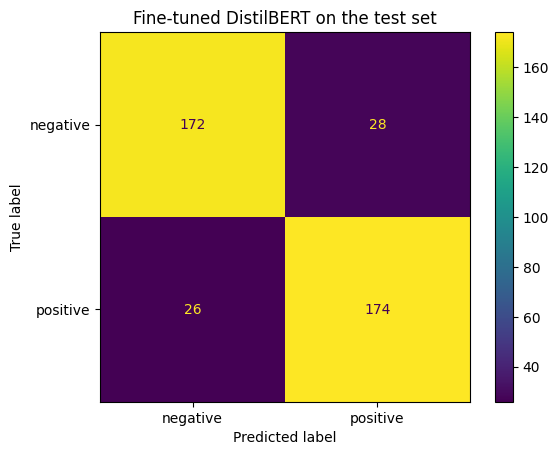

In [32]:
test_out = trainer.predict(tokenized["test"])
test_probs = F.softmax(
    torch.tensor(test_out.predictions, dtype=torch.float32), dim=-1
).numpy()
pred_ft = test_probs.argmax(-1)
record(f"DistilBERT fine-tuned (head, {MAX_LEN} tokens)", pred_ft)
show_leaderboard()

print(
    classification_report(
        y_test, pred_ft, target_names=["negative", "positive"], digits=4
    )
)
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_ft, display_labels=["negative", "positive"]
)
plt.title("Fine-tuned DistilBERT on the test set")
plt.show()

### 🪜 What did fine-tuning buy?

Is that a lot? The table above compares fine-tuning with _other methods_. To measure what **fine-tuning** itself adds, compare the same pretrained DistilBERT **without** fine-tuning:

- **random head**: the model of Section 5.5 before any training step (pretrained encoder, random head);
- **frozen encoder + logistic regression** (a _linear probe_): the pretrained DistilBERT is a fixed feature extractor; the `[CLS]` vector of its last layer (the vector the classification head reads) goes into a logistic regression, as the mean GloVe vectors did in the word embeddings lab. Only the logistic regression is trained; the encoder never changes.

Fine-tuning differs from the probe in one thing only: the gradient also flows into the 66M parameters of the encoder.

> 🎲 **Bet:** how many points does fine-tuning add over the frozen probe?


In [33]:
# Reference 1: the pretrained encoder with a random head, before any training step
untrained = make_trainer(
    fresh_model(), tokenized["train"], tokenized["validation"], "runs/untrained"
)
record(
    "DistilBERT, random head (no training)",
    untrained.predict(tokenized["test"]).predictions.argmax(-1),
)
del untrained

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT, random head (no training)         accuracy 0.4925   macro-F1 0.3944


In [34]:
# Reference 2: frozen encoder + logistic regression on the [CLS] vector, a "linear probe" (≈ 1 min on GPU)
from transformers import AutoModel
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

frozen_encoder = (
    AutoModel.from_pretrained(CHECKPOINT).to(DEVICE).eval()
)  # the pretrained DistilBERT, never trained here


def cls_pool(last_hidden_state, attention_mask):
    return last_hidden_state[:, 0]  # the vector of the first token, [CLS]


@torch.no_grad()
def frozen_features(texts, pool, encoder=frozen_encoder, batch_size=32):
    # one vector per text: the last layer of the frozen encoder, reduced to [B, d] by `pool`
    vecs = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(
            texts[i : i + batch_size],
            truncation=True,
            max_length=MAX_LEN,
            padding=True,
            return_tensors="pt",
        ).to(DEVICE)
        h = encoder(**enc).last_hidden_state  # [B, T, d]
        vecs.append(pool(h, enc["attention_mask"]).float().cpu())
    return torch.cat(vecs).numpy()


def linear_probe(pool, name):
    # frozen features -> standardized -> logistic regression (C=0.1: 768 features for 1,400 reviews)
    X_train = frozen_features(list(reviews["train"]["text"]), pool)
    X_test = frozen_features(list(reviews["test"]["text"]), pool)
    probe = make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=5000, C=0.1, random_state=SEED)
    )
    probe.fit(X_train, list(reviews["train"]["label"]))
    record(name, probe.predict(X_test))


linear_probe(cls_pool, f"frozen DistilBERT, [CLS] vector + LR ({MAX_LEN} tokens)")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


frozen DistilBERT, [CLS] vector + LR (512 tokens) accuracy 0.7775   macro-F1 0.7773


,system,what is trained,test accuracy
0,majority class,nothing,0.5000
1,"DistilBERT, random head (no training)",nothing: pretrained encoder + random head,0.4925
2,"frozen DistilBERT, [CLS] vector + LR (512 tokens)",a logistic regression on frozen features,0.7775
3,"DistilBERT fine-tuned (head, 512 tokens)",all 67M parameters (first tokens of the review),0.8650


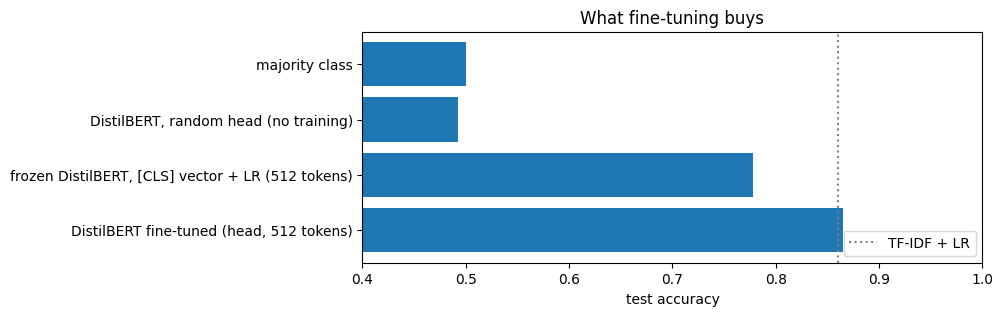

In [35]:
# The fine-tuning ladder: the same pretrained DistilBERT, trained more and more
LADDER = {
    "majority class": "nothing",
    "DistilBERT, random head (no training)": "nothing: pretrained encoder + random head",
    f"frozen DistilBERT, [CLS] vector + LR ({MAX_LEN} tokens)": "a logistic regression on frozen features",
    f"DistilBERT fine-tuned (head, {MAX_LEN} tokens)": "all 67M parameters (first tokens of the review)",
    f"DistilBERT fine-tuned (head+tail, {MAX_LEN} tokens)": "all 67M parameters (beginning + end of the review)",
}


def show_ladder():
    rows = [
        (name, what, LEADERBOARD[name])
        for name, what in LADDER.items()
        if name in LEADERBOARD
    ]
    display(
        pd.DataFrame(
            rows, columns=["system", "what is trained", "test accuracy"]
        ).round(4)
    )
    plt.figure(figsize=(8, 0.5 * len(rows) + 1))
    plt.barh([r[0] for r in rows][::-1], [r[2] for r in rows][::-1], color="C0")
    plt.axvline(
        LEADERBOARD["TF-IDF + LR"], color="gray", linestyle=":", label="TF-IDF + LR"
    )
    plt.xlim(0.4, 1.0)
    plt.xlabel("test accuracy")
    plt.legend(loc="lower right")
    plt.title("What fine-tuning buys")
    plt.show()


show_ladder()

🤔 **Discuss.** The frozen encoder already "knows" English: why is a logistic regression on its `[CLS]` vector so far from fine-tuning? What changes inside the encoder during fine-tuning?


## 🔎 5.9 Error analysis: the most confident mistakes

Averages hide what the model does wrong. Look at the reviews where the model was **wrong** and **confident**: they often reveal problems in the data, in the preprocessing, or in the task itself. Remember that the model read only the first `MAX_LEN` tokens: the cell prints the beginning **and** the end of each review.


In [36]:
wrong = np.where(pred_ft != y_test)[0]
conf = test_probs[wrong, pred_ft[wrong]]  # confidence of the wrong prediction
for i in wrong[np.argsort(-conf)][:4]:
    text = reviews["test"][int(i)]["text"]
    n_tok = len(tokenizer(text)["input_ids"])
    print(
        f"test review {i} | TRUE {id2label[y_test[i]]:8s} | PREDICTED {id2label[pred_ft[i]]} "
        f"with P = {test_probs[i, pred_ft[i]]:.3f} | {n_tok} tokens (the model read {min(n_tok, MAX_LEN)})"
    )
    print("  BEGINNING:", text[:400].replace("\n", " "), "...")
    print("  END:      ...", text[-400:].replace("\n", " "))
    print("-" * 110)

test review 20 | TRUE negative | PREDICTED positive with P = 0.982 | 1290 tokens (the model read 512)
  BEGINNING: i can imagine how good krippendorf's tribe must have looked on paper .  it does not surprise me in the least that a group of extremely talented actors , led by the great richard dreyfuss and a good director ( todd holland ) , all wanted to make this film .  in fact , it is only the expertise by which this excruciatingly bad script has been executed that keeps me from suggesting that you stay as fa ...
  END:      ... thing but boring .  and if you're less serious than i , you probably will enjoy it .  i , however , can't get past these elements .  krippendorf's tribe is being marketed as a family comedy , but this is the kind of film that teaches the kids of our society faulty lessons that they shouldn't be learning .  with a little more insight into its story and themes , this could have been a good movie .  
---------------------------------------------------------------

🤔 **Discuss.** For each mistake: did the model have a chance (was the verdict inside the first `MAX_LEN` tokens)? Is the review ironic, mixed, mostly plot? Would TF-IDF, which reads the whole review, get it right? (Check with `PREDICTIONS["TF-IDF + LR"][i]`.)


## ⚖️ 5.10 Is the difference significant?

With 400 test reviews, one review is worth 0.25 points of accuracy. Is the difference between the fine-tuned model and TF-IDF **real**, or luck of this particular test set? This is the **paired bootstrap** of Lecture 07, which you implemented in the NLTK lab (exercise B3): resample the test set many times and count how often the advantage of A over B is at least twice the observed one.

> 🔍 **The test is one-sided.** `paired_bootstrap(A, B)` asks _"is A better than B?"_. If the observed δ is **negative** (B is ahead), its p-value is meaningless: to ask whether B is better, swap the two systems, `compare(B, A)`.


In [37]:
def paired_bootstrap(correct_a, correct_b, b=10000, seed=0):
    # Input: two 0/1 arrays (1 = the system got that test item right). Output: (delta accuracy, p-value)
    rng = np.random.default_rng(seed)
    diff = np.asarray(correct_a, dtype=int) - np.asarray(correct_b, dtype=int)
    delta = diff.mean()
    samples = rng.integers(
        0, len(diff), size=(b, len(diff))
    )  # b virtual test sets, drawn with replacement
    deltas = diff[samples].mean(axis=1)
    return delta, float(np.mean(deltas >= 2 * delta))


def compare(a, b):
    delta, p = paired_bootstrap(PREDICTIONS[a] == y_test, PREDICTIONS[b] == y_test)
    print(f"{a}  vs  {b}:  delta = {delta:+.4f}, p = {p:.4f}")


for other in ["TF-IDF + LR", "DistilBERT fine-tuned on SST-2 (not on our reviews)"]:
    if other in PREDICTIONS:
        compare(f"DistilBERT fine-tuned (head, {MAX_LEN} tokens)", other)

DistilBERT fine-tuned (head, 512 tokens)  vs  TF-IDF + LR:  delta = +0.0050, p = 0.4374
DistilBERT fine-tuned (head, 512 tokens)  vs  DistilBERT fine-tuned on SST-2 (not on our reviews):  delta = +0.0125, p = 0.2783


## ✂️ 5.11 Read the end of the review: head + tail truncation

The error analysis and the length histogram tell the same story: 512 tokens is less than the median review, so `truncation=True` keeps only the **beginning**, often the plot, while a critic usually states the verdict at the **end**. Sun et al. (2019, _How to fine-tune BERT for text classification?_) compared truncation strategies on long movie reviews (IMDb) and found that keeping the **first 128 and the last 382 tokens** worked best.

`head_tail_encode(text, tokenizer, max_length, head)` implements it:

- if the review fits (at most `max_length - 2` tokens without special tokens), the usual encoding: `[CLS] + tokens + [SEP]`;
- otherwise `[CLS] + the first head tokens + the last (max_length - 2 - head) tokens + [SEP]`, exactly `max_length` ids.

For example, with `max_length=10, head=3`, a review of 20 tokens $t_1 \dots t_{20}$ becomes `[CLS] t1 t2 t3 t16 t17 t18 t19 t20 [SEP]`.


In [38]:
def head_tail_encode(text, tokenizer, max_length=512, head=128):
    ids = tokenizer(text, add_special_tokens=False)[
        "input_ids"
    ]  # the tokens, without [CLS] / [SEP]
    budget = max_length - 2  # room left for [CLS] and [SEP]
    if len(ids) > budget:
        tail = budget - head
        ids = ids[:head] + (
            ids[-tail:] if tail > 0 else []
        )  # careful: ids[-0:] would be the WHOLE list
    ids = [tokenizer.cls_token_id] + ids + [tokenizer.sep_token_id]
    return {"input_ids": ids, "attention_mask": [1] * len(ids)}


# a small example: the numbers 0 ... 39 (one token each), max_length 12, head 3
demo = " ".join(str(i) for i in range(40))
print(
    tokenizer.convert_ids_to_tokens(
        head_tail_encode(demo, tokenizer, max_length=12, head=3)["input_ids"]
    )
)

['[CLS]', '0', '1', '2', '33', '34', '35', '36', '37', '38', '39', '[SEP]']


Now we retrain the model of Section 5.5 with **exactly the same recipe** (`make_trainer`, same seed, same hyperparameters), changing **only** the truncation. With `MAX_LEN = 512` the head is 128 tokens, as in the paper; with the CPU budget (`MAX_LEN = 128`) we keep a head of 32 tokens.

> 🎲 **Bet:** how many points will reading the end of the review be worth? Will the difference with head-only truncation be significant?


Map:   0%|          | 0/1400 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.599846,0.351321,0.860000,0.878310,0.860000,0.858285
2,0.210526,0.224765,0.910000,0.910657,0.910000,0.909964
3,0.042792,0.264710,0.900000,0.901445,0.900000,0.899910


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

training time: 165 s


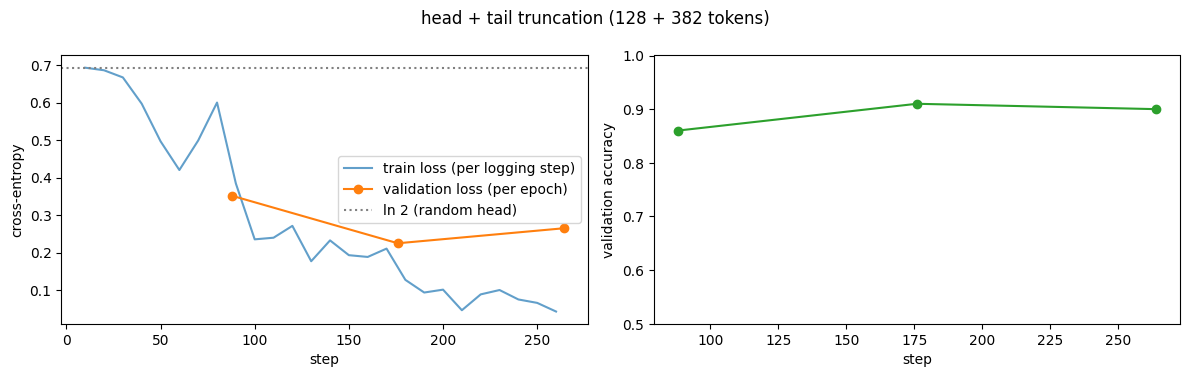

DistilBERT fine-tuned (head+tail, 512 tokens) accuracy 0.8825   macro-F1 0.8823


,test accuracy
"DistilBERT fine-tuned (head+tail, 512 tokens)",0.8825
"DistilBERT fine-tuned (head, 512 tokens)",0.8650
TF-IDF + LR,0.8600
DistilBERT fine-tuned on SST-2 (not on our reviews),0.8525
"frozen DistilBERT, [CLS] vector + LR (512 tokens)",0.7775
majority class,0.5000
"DistilBERT, random head (no training)",0.4925


DistilBERT fine-tuned (head+tail, 512 tokens)  vs  DistilBERT fine-tuned (head, 512 tokens):  delta = +0.0175, p = 0.2050
DistilBERT fine-tuned (head+tail, 512 tokens)  vs  TF-IDF + LR:  delta = +0.0225, p = 0.1542


,system,what is trained,test accuracy
0,majority class,nothing,0.5000
1,"DistilBERT, random head (no training)",nothing: pretrained encoder + random head,0.4925
2,"frozen DistilBERT, [CLS] vector + LR (512 tokens)",a logistic regression on frozen features,0.7775
3,"DistilBERT fine-tuned (head, 512 tokens)",all 67M parameters (first tokens of the review),0.8650
4,"DistilBERT fine-tuned (head+tail, 512 tokens)",all 67M parameters (beginning + end of the rev...,0.8825


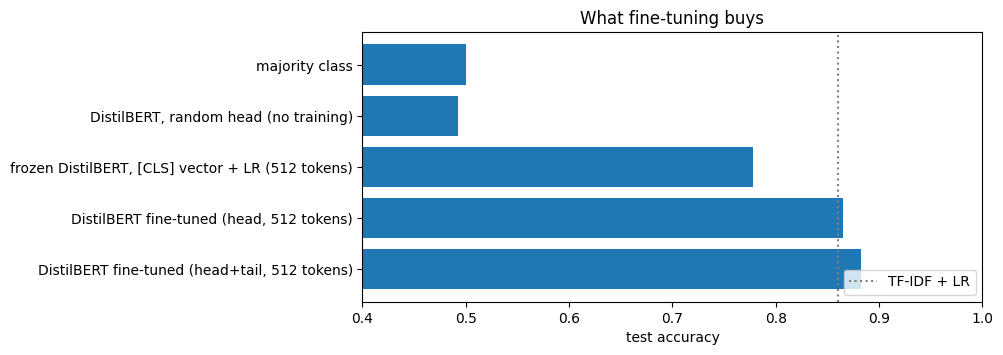

In [39]:
HEAD = 128 if MAX_LEN == 512 else 32
tokenized_ht = reviews.map(
    lambda ex: head_tail_encode(ex["text"], tokenizer, MAX_LEN, HEAD)
)

trainer_ht = make_trainer(
    fresh_model(),
    tokenized_ht["train"],
    tokenized_ht["validation"],
    "runs/distilbert-headtail",
)
t0 = time.perf_counter()
trainer_ht.train()
print(f"training time: {time.perf_counter() - t0:.0f} s")
plot_history(
    trainer_ht, f"head + tail truncation ({HEAD} + {MAX_LEN - 2 - HEAD} tokens)"
)

name_ht = f"DistilBERT fine-tuned (head+tail, {MAX_LEN} tokens)"
record(name_ht, trainer_ht.predict(tokenized_ht["test"]).predictions.argmax(-1))
show_leaderboard()
compare(name_ht, f"DistilBERT fine-tuned (head, {MAX_LEN} tokens)")
compare(name_ht, "TF-IDF + LR")
show_ladder()

🤔 **Discuss.**

- Go back to the most confident mistakes of Section 5.9 (`PREDICTIONS[name_ht][i]`): are they still mistakes?
- Head + tail vs head-only, and head + tail vs TF-IDF: which differences are significant? What would you write in a report?
- What would happen with `HEAD = 0` (tail only)? Try it.


## 💾 5.12 Save, reload, share

We save our best model, the head + tail one. A fine-tuned model is a folder: the configuration (with `id2label`), the weights (`model.safetensors`) and the tokenizer files. Save the tokenizer **with** the model: one is useless without the other.


In [40]:
SAVE_DIR = "my-distilbert-movie-reviews"
trainer_ht.save_model(
    SAVE_DIR
)  # our best model (head + tail, best epoch) + the tokenizer (processing_class)
for f in sorted(os.listdir(SAVE_DIR)):
    print(f"{f:28s} {os.path.getsize(os.path.join(SAVE_DIR, f)) / 1e6:8.2f} MB")

my_classifier = pipeline("text-classification", model=SAVE_DIR, device=DEVICE)
my_classifier([
    "an absolute masterpiece , i was moved to tears .",
    "two hours of my life i will never get back .",
    "the first half is boring , but the ending is spectacular and worth the wait .",
])

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

config.json                      0.00 MB
model.safetensors              267.83 MB
tokenizer.json                   0.71 MB
tokenizer_config.json            0.00 MB
training_args.bin                0.01 MB


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'positive', 'score': 0.8576072454452515},
 {'label': 'negative', 'score': 0.5819767713546753},
 {'label': 'positive', 'score': 0.9322847723960876}]

> 🔍 **Sharing on the Hub.** To share the model with your group (or with the world), log in with a _write_ token and push it:
>
> ```python
> from huggingface_hub import login
> login()                                                    # paste a token from huggingface.co/settings/tokens
> trainer_ht.push_to_hub("my-distilbert-movie-reviews")         # creates username/my-distilbert-movie-reviews
> ```
>
> Then anyone can load it with `pipeline("text-classification", model="username/my-distilbert-movie-reviews")`. Write a **model card**: data, splits, hyperparameters, results, limitations. And remember that a Colab runtime is wiped when it disconnects: save to Google Drive or to the Hub what you want to keep.


## 🪶 5.13 LoRA: fine-tune 1% of the parameters

Full fine-tuning (Section 5.6) updates all 67M parameters, and saves a full copy of the model for every task. For a 7-billion-parameter LLM this is out of reach on a Colab GPU. **Parameter-efficient fine-tuning** freezes the pretrained weights and trains a few new ones; **LoRA** (Low-Rank Adaptation, Hu et al., 2022) is the most common method.

### 🧮 The equations of Lecture 18

Take one dense layer of the transformer, with pretrained weight matrix $W$ of size $[k \times d]$ (input of size $k$, output of size $d$). Full fine-tuning would learn an update $\Delta W$, also of size $[k \times d]$. LoRA writes the update as the product of two thin matrices:

$$\Delta W = AB, \qquad A \text{ is } [k \times r],\quad B \text{ is } [r \times d],\quad r \ll k, d$$

and the layer computes

$$h = xW + \frac{\alpha}{r}\, xAB \qquad \text{(SLP Eq. 8.1, with the scaling factor } \alpha / r \text{)}$$

- $W$ is **frozen**: no gradient and no optimizer state for it;
- only $A$ and $B$ are **trained**: $r\,(k + d)$ numbers instead of $k \cdot d$;
- at the start $A$ is random and $B = 0$, so $AB = 0$: the model starts **exactly** as the pretrained one;
- after training, $W + \frac{\alpha}{r} AB$ can be computed once: **no extra cost at inference**.

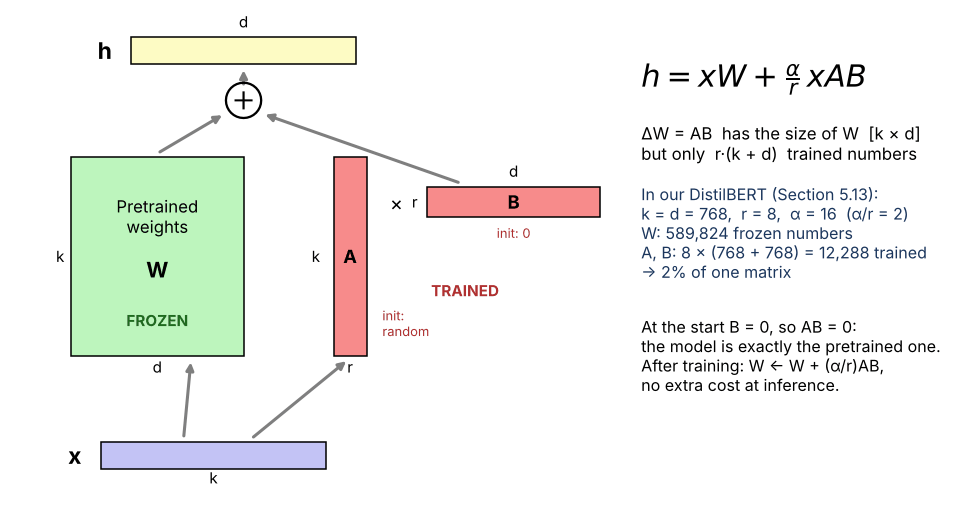

> 🔍 **The factor $\alpha / r$.** Lecture 18 writes $h = xW + xAB$. The `peft` library multiplies the update by a constant $\alpha / r$ (`lora_alpha / r`), so that changing the rank $r$ does not change the scale of the update, and the learning rate that works. With `r=8, lora_alpha=16` the factor is 2. The trained matrices are still $A$ and $B$.

The next cell is the _LoRA by hand_ exercise of Lecture 18, in PyTorch.


In [41]:
# 🧮 LoRA by hand: the exercise of Lecture 18 (k = d = 3, r = 1, no scaling)
x = torch.tensor([[1.0, 2.0, 1.0]])  # [1 × k]
W = torch.eye(3)  # [k × d]: frozen (here the identity)
A = torch.tensor([[1.0], [0.0], [1.0]])  # [k × r]: trained
B = torch.tensor([[2.0, 1.0, 0.0]])  # [r × d]: trained

print("xW  =", (x @ W).tolist())
print("xA  =", (x @ A).tolist(), "  (r = 1 number)")
print("xAB =", (x @ A @ B).tolist())
print("h   =", (x @ W + x @ A @ B).tolist(), "  = xW + xAB")
print("AB  =", (A @ B).tolist())
print(
    f"ΔW = AB has {(A @ B).numel()} entries, built from {A.numel() + B.numel()} trained parameters"
)

xW  = [[1.0, 2.0, 1.0]]
xA  = [[2.0]]   (r = 1 number)
xAB = [[4.0, 2.0, 0.0]]
h   = [[5.0, 4.0, 1.0]]   = xW + xAB
AB  = [[2.0, 1.0, 0.0], [0.0, 0.0, 0.0], [2.0, 1.0, 0.0]]
ΔW = AB has 9 entries, built from 6 trained parameters


### 🎯 Where LoRA goes in our model

A transformer has many matrices $W$: $W^Q, W^K, W^V, W^O$ in every attention layer and the two matrices of every feedforward layer. You choose which ones get an adapter. As in the original LoRA paper, we adapt only $W^Q$ and $W^V$ of the 6 layers of DistilBERT. The classification head is new (random), so it is trained fully, without LoRA.

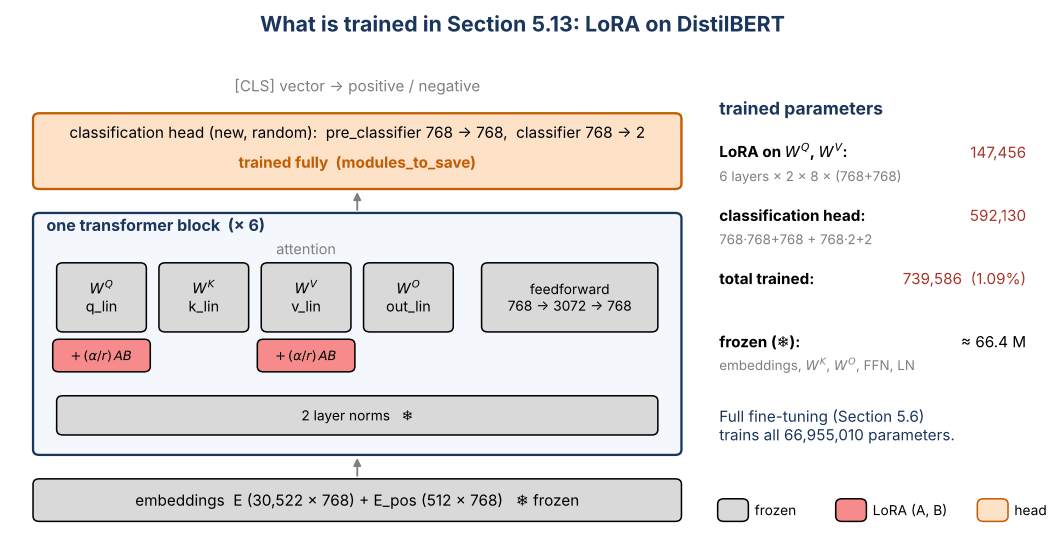

How the arguments of `LoraConfig` map onto the equations:

| in the equations             | in the code                         | in our DistilBERT                                      |
| ---------------------------- | ----------------------------------- | ------------------------------------------------------ |
| which LoRA matrices $W$      | `target_modules=["q_lin", "v_lin"]` | $W^Q$ and $W^V$ of each of the 6 layers, $k = d = 768$ |
| the rank $r$                 | `r=8`                               | $A$ is $[768 \times 8]$, $B$ is $[8 \times 768]$       |
| the scaling $\alpha / r$     | `lora_alpha=16`                     | $\alpha / r = 2$                                       |
| dropout on the LoRA path     | `lora_dropout=0.1`                  | applied to $x$ before $A$, during training only        |
| trained fully, not with LoRA | `modules_to_save=[...]`             | the new head: `pre_classifier`, `classifier`           |


In [42]:
from peft import LoraConfig, get_peft_model, TaskType

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,  # the rank r
    lora_alpha=16,  # the update AB is scaled by alpha / r
    lora_dropout=0.1,
    target_modules=[
        "q_lin",
        "v_lin",
    ],  # DistilBERT's W^Q and W^V (names differ by model: print(model) to find them)
    modules_to_save=[
        "pre_classifier",
        "classifier",
    ],  # the new head is trained fully (it is not pretrained!)
)
lora_model = get_peft_model(fresh_model(), lora_config)
lora_model.print_trainable_parameters()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 739,586 || all params: 67,694,596 || trainable%: 1.0925


In [43]:
# 🔍 Look inside one adapted matrix: W^Q of the first layer
q = lora_model.base_model.model.distilbert.transformer.layer[0].attention.q_lin
print(q)  # the original Linear, wrapped: base_layer (W) + lora_A + lora_B

# PyTorch's nn.Linear stores its weight TRANSPOSED ([out × in]) and computes x @ weight.T:
# so the lecture's W, A, B are the transposes of the stored weights
W_ = q.base_layer.weight.T  # [k × d]
A_ = q.lora_A["default"].weight.T  # [k × r]
B_ = q.lora_B["default"].weight.T  # [r × d]
print(f"\nW: {tuple(W_.shape)}  trainable: {W_.requires_grad}")
print(f"A: {tuple(A_.shape)}    trainable: {A_.requires_grad}")
print(
    f"B: {tuple(B_.shape)}    trainable: {B_.requires_grad}   all zeros at the start: {bool((B_ == 0).all())}"
)
print(f"alpha / r = {q.scaling['default']}")

lora.Linear(
  (base_layer): Linear(in_features=768, out_features=768, bias=True)
  (lora_dropout): ModuleDict(
    (default): Dropout(p=0.1, inplace=False)
  )
  (lora_A): ModuleDict(
    (default): Linear(in_features=768, out_features=8, bias=False)
  )
  (lora_B): ModuleDict(
    (default): Linear(in_features=8, out_features=768, bias=False)
  )
  (lora_embedding_A): ParameterDict()
  (lora_embedding_B): ParameterDict()
  (lora_magnitude_vector): ModuleDict()
)

W: (768, 768)  trainable: False
A: (768, 8)    trainable: True
B: (8, 768)    trainable: True   all zeros at the start: True
alpha / r = 2.0


LoRA needs a **higher learning rate** than full fine-tuning (the adapters start from zero and are few). Same data, same epochs, same evaluation; to compare with the full fine-tuning of Section 5.11 we use the same **head + tail** truncation (using `tokenized_ht`!):


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.365266,0.312963,0.860000,0.867197,0.860000,0.859311
2,0.255295,0.245815,0.900000,0.900160,0.900000,0.899990
3,0.131389,0.267946,0.890000,0.892512,0.890000,0.889824


training time: 55 s


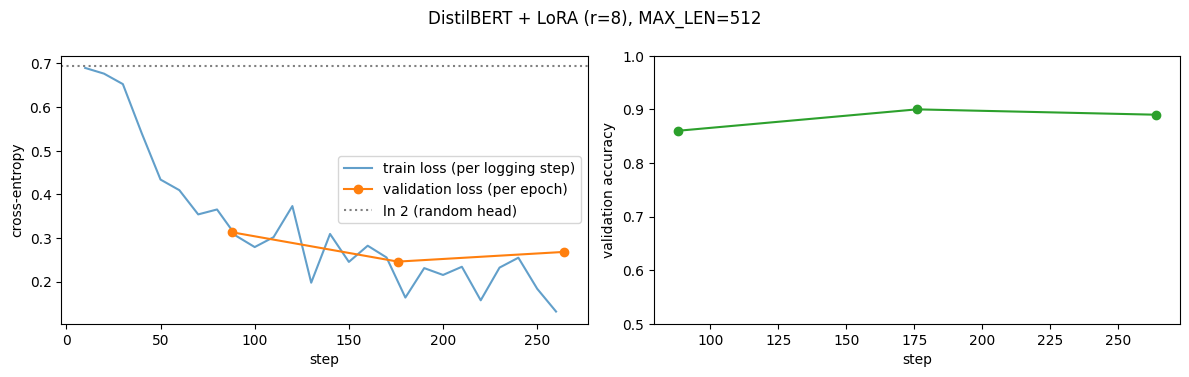

DistilBERT LoRA r=8 (head+tail, 512 tokens)   accuracy 0.8850   macro-F1 0.8849


,test accuracy
"DistilBERT LoRA r=8 (head+tail, 512 tokens)",0.8850
"DistilBERT fine-tuned (head+tail, 512 tokens)",0.8825
"DistilBERT fine-tuned (head, 512 tokens)",0.8650
TF-IDF + LR,0.8600
DistilBERT fine-tuned on SST-2 (not on our reviews),0.8525
"frozen DistilBERT, [CLS] vector + LR (512 tokens)",0.7775
majority class,0.5000
"DistilBERT, random head (no training)",0.4925


adapter on disk: 3.0 MB (the full model: 268 MB)


In [44]:
lora_trainer = make_trainer(
    lora_model,
    tokenized_ht["train"],
    tokenized_ht["validation"],
    "runs/distilbert-lora",
    learning_rate=5e-4,
)

t0 = time.perf_counter()
lora_trainer.train()
print(f"training time: {time.perf_counter() - t0:.0f} s")
plot_history(lora_trainer, f"DistilBERT + LoRA (r=8), MAX_LEN={MAX_LEN}")

record(
    f"DistilBERT LoRA r=8 (head+tail, {MAX_LEN} tokens)",
    lora_trainer.predict(tokenized_ht["test"]).predictions.argmax(-1),
)

show_leaderboard()

lora_model.save_pretrained("my-lora-adapter")  # saves ONLY the adapters (+ the head)
size = sum(
    os.path.getsize(os.path.join("my-lora-adapter", f))
    for f in os.listdir("my-lora-adapter")
)
print(
    f"adapter on disk: {size / 1e6:.1f} MB (the full model: {os.path.getsize(os.path.join(SAVE_DIR, 'model.safetensors')) / 1e6:.0f} MB)"
)

🤔 **Discuss.** How many of the trainable parameters belong to the LoRA matrices, and how many to the head? Is training faster than full fine-tuning? Why not by a factor of 100? (Think about which computations are still needed in the forward and backward passes.)


### 🔬 What did LoRA learn?

After training, the update of $W^Q$ in the first layer is $\Delta W = \frac{\alpha}{r} AB$: a $768 \times 768$ matrix built from $2 \times 768 \times 8$ numbers, so its **rank is at most 8**. Full fine-tuning also changed the same matrix, but without any constraint: $\Delta W_{\text{full}} = W_{\text{fine-tuned}} - W_{\text{pretrained}}$.

For the full update the next cell uses the model of Section 5.6 (head-only truncation; replace `trainer` with `trainer_ht` to use the head + tail model of Section 5.11, trained on the same inputs as LoRA). It compares the two updates through their **singular values** (the SVD of linear algebra: a matrix of rank $r$ has exactly $r$ non-zero singular values). If most of the full update lives in a few directions, a low-rank update loses little: this is the _low intrinsic dimension_ argument of Lecture 18 (Aghajanyan et al., 2021).


rank of ΔW, LoRA:    8   (at most r = 8)
rank of ΔW, full:  767   (out of 768)
size of the update, ‖ΔW‖ / ‖W‖:  LoRA 0.0264   full 0.0091
share of the full update in its 8 largest directions: 35.6%


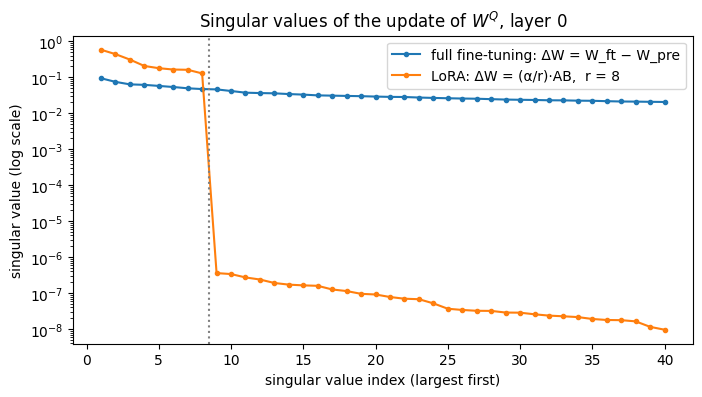

In [45]:
# The LoRA update vs the full fine-tuning update of W^Q in the first layer
q = lora_model.base_model.model.distilbert.transformer.layer[0].attention.q_lin
with torch.no_grad():
    dW_lora = (
        (q.scaling["default"] * q.lora_B["default"].weight @ q.lora_A["default"].weight)
        .T.float()
        .cpu()
    )  # (α/r)·AB, [k × d]
    W_pre = (
        frozen_encoder.transformer.layer[0].attention.q_lin.weight.T.float().cpu()
    )  # pretrained W (the frozen encoder of 5.8)
    W_full = (
        trainer.model.distilbert.transformer
        .layer[0]
        .attention.q_lin.weight.T.float()
        .cpu()
    )  # W after full fine-tuning (5.6)
    dW_full = W_full - W_pre
    s_lora, s_full = torch.linalg.svdvals(dW_lora), torch.linalg.svdvals(dW_full)

print(
    f"rank of ΔW, LoRA: {torch.linalg.matrix_rank(dW_lora).item():4d}   (at most r = 8)"
)
print(
    f"rank of ΔW, full: {torch.linalg.matrix_rank(dW_full).item():4d}   (out of {dW_full.shape[0]})"
)
print(
    f"size of the update, ‖ΔW‖ / ‖W‖:  LoRA {(dW_lora.norm() / W_pre.norm()).item():.4f}   full {(dW_full.norm() / W_pre.norm()).item():.4f}"
)
top8 = ((s_full[:8] ** 2).sum() / (s_full**2).sum()).item()
print(f"share of the full update in its 8 largest directions: {top8:.1%}")

n = min(40, len(s_full))  # the 40 largest singular values
plt.figure(figsize=(8, 4))
plt.semilogy(
    range(1, n + 1),
    s_full[:n].numpy(),
    marker="o",
    ms=3,
    label="full fine-tuning: ΔW = W_ft − W_pre",
)
plt.semilogy(
    range(1, n + 1),
    s_lora[:n].clamp(min=1e-9).numpy(),
    marker="o",
    ms=3,
    label="LoRA: ΔW = (α/r)·AB,  r = 8",
)
plt.axvline(8.5, color="gray", linestyle=":")
plt.xlabel("singular value index (largest first)")
plt.ylabel("singular value (log scale)")
plt.title("Singular values of the update of $W^Q$, layer 0")
plt.legend()
plt.show()

Finally, the "no extra cost at inference" claim: `merge_and_unload` computes $W \leftarrow W + \frac{\alpha}{r} AB$ in every adapted layer and returns a plain DistilBERT, without any LoRA module. Its outputs must be the same as those of the model with adapters, up to floating-point rounding: the merged layer computes $x(W + \frac{\alpha}{r}AB)$ instead of $xW + \frac{\alpha}{r}xAB$, the same numbers added in a different order.


In [46]:
# Merge the adapters into W, and check that the outputs do not change
import copy

merged = copy.deepcopy(
    lora_model
).merge_and_unload()  # a plain DistilBertForSequenceClassification
lora_model.eval()
merged.eval()
batch = {k: v.to(merged.device) for k, v in collate(features).items() if k != "labels"}
with torch.no_grad():
    gap = (lora_model(**batch).logits - merged(**batch).logits).abs().max().item()
print(f"largest difference between the logits: {gap:.1e}")
print(
    f"{type(merged).__name__}: {merged.num_parameters():,} parameters, "
    f"LoRA modules left: {sum('lora' in n for n, _ in merged.named_modules())}"
)
del merged

largest difference between the logits: 1.0e-03
DistilBertForSequenceClassification: 66,955,010 parameters, LoRA modules left: 0


# 🗺 6. Take-away map and a cheat sheet for your project

```text
text ──tokenizer──▶ input_ids, attention_mask ──model body──▶ hidden states [B, T, d] ──head──▶ logits ──▶ softmax / argmax / generate
```

| your task                                       | Auto class                           | head on top of the body                          | `labels`                                                                 |
| ----------------------------------------------- | ------------------------------------ | ------------------------------------------------ | ------------------------------------------------------------------------ |
| classify a text (or a pair)                     | `AutoModelForSequenceClassification` | linear layer on `[CLS]`                          | one int per text                                                         |
| tag every token (NER, PoS)                      | `AutoModelForTokenClassification`    | linear layer on every token                      | one int per token, `-100` on special tokens and on continuation subwords |
| masked LM (continue pretraining on your domain) | `AutoModelForMaskedLM`               | unembedding                                      | from `DataCollatorForLanguageModeling`                                   |
| generate text / chat                            | `AutoModelForCausalLM`               | unembedding (LM head)                            | the input ids; `-100` on the prompt                                      |
| translate / summarize (encoder-decoder)         | `AutoModelForSeq2SeqLM`              | LM head of the decoder                           | the target ids                                                           |
| vectors only (retrieval, clustering, probing)   | `AutoModel`                          | none: use `last_hidden_state` or `hidden_states` | —                                                                        |

### 🧰 Common pitfalls

- **Mismatched tokenizer and model**: always load both from the same name (or the same folder).
- **Labels**: classification wants `labels` as integers in `0 … num_labels-1`; set `id2label`/`label2id`; `-100` means "ignore this position".
- **Inference**: call `model.eval()` and wrap with `torch.no_grad()`; put the inputs on the same device as the model (`.to(DEVICE)`).
- **GPT-style tokenizers have no pad token**: set `tok.pad_token = tok.eos_token` before padding a batch, and pass `pad_token_id` to `generate`.
- **Out of GPU memory**: lower `per_device_train_batch_size` and raise `gradient_accumulation_steps` (same effective batch); lower `max_length`; use `fp16`/`bf16`; use LoRA; restart the runtime to free memory.
- **Splits**: choose hyperparameters and checkpoints on **validation**, report **test** once. Fix the seeds, and when you can, report the mean over a few seeds.
- **Baselines**: always report at least a majority-class baseline and a classic one (TF-IDF + LR). A transformer that does not beat TF-IDF is a finding, not a failure, if you can explain why.


# 🏋️ Exercises

Nothing is graded: it is just for fun and understanding.

|      | Exercise                                  | You will learn                                                                              |
| ---- | ----------------------------------------- | ------------------------------------------------------------------------------------------- |
| 🏋️ 1 | 🪟 Read the whole review: sliding windows | long inputs of any length: chunk, predict, aggregate (also for summarization and retrieval) |
| 🏋️ 2 | 🤖 An LLM as a zero-shot classifier       | prompting with chat templates, parsing outputs, LLM vs fine-tuned encoder                   |

They all use the cells above (the `reviews`, `tokenizer`, `make_trainer`, `record`...): run the whole notebook first. Exercise 1 runs the two fine-tuned DistilBERT models on every window of the 400 test reviews, and Exercise 2 runs the chat model of Section 4.3 on 100 reviews: use a GPU runtime.

### 🧑‍💻 How to work on an exercise

1. Read the box **✏️ What you have to write**: it gives the names of the functions, what goes in (**input**) and what must come out (**output**).
2. Write your code in the cells marked `# ✏️ YOUR CODE HERE`. Stuck? Read the **💡 Hints**, one at a time.
3. Run the **🧪 check** cell: ✅ correct · ❌ something is off (the message tells you what) · ⏳ not implemented yet.
4. Run the **▶️ Given** cells: they use your code to train, evaluate and update the leaderboard.


## 🪟 Exercise 1. Read the whole review: sliding windows

Section 5.11 squeezed each review into 512 tokens by keeping its beginning and its end: the middle is still thrown away. Another approach works for inputs of **any length** and for **any task** with long inputs (long documents, reports to summarize, transcripts, documents to index for retrieval): cut the input into overlapping **windows** of at most 512 tokens, run the model on every window, and **aggregate** the predictions (here: average the probabilities). Nothing is thrown away; the price is one forward pass per window.

#### ✏️ What you have to write: `split_into_windows(ids, size, stride)`

- **Input:** a list of token ids (without special tokens), the window `size`, and the `stride` (the distance between the starts of two consecutive windows, with `stride <= size`).
- **Output:** a list of windows (lists of ids): `ids[0:size]`, `ids[stride:stride+size]`, `ids[2*stride:2*stride+size]`, ..., stopping at the **first window that reaches the end** of `ids`. A list not longer than `size` gives a single window, `[ids]`.

**Worked example.**

- `split_into_windows([0, 1, ..., 9], size=4, stride=3)` → `[[0, 1, 2, 3], [3, 4, 5, 6], [6, 7, 8, 9]]`
- `split_into_windows([0, 1, ..., 10], size=4, stride=3)` → `[[0, 1, 2, 3], [3, 4, 5, 6], [6, 7, 8, 9], [9, 10]]`
- `split_into_windows([5, 6], size=4, stride=3)` → `[[5, 6]]`

> 💡 **Hints**
>
> - A `while` loop over the start position: append `ids[start:start + size]`, stop when `start + size >= len(ids)`, otherwise move `start` forward by `stride`.
> - With `stride < size` consecutive windows overlap: a sentence cut in two by one window is whole in the next one.


In [47]:
# ✏️ YOUR CODE HERE
def split_into_windows(ids, size, stride):
    """Input: a list of ids, the window size, the stride (<= size).
    Output: [ids[0:size], ids[stride:stride+size], ...] up to the first window that reaches the end of ids."""
    # TODO
    return None

In [48]:
# 🧪 Check Exercise 1
def _check_ex1():
    try:
        out = split_into_windows(list(range(10)), 4, 3)
        if out is None:
            return _todo("split_into_windows")
        out = [list(w) for w in out]
        cases = [
            ((list(range(10)), 4, 3), [[0, 1, 2, 3], [3, 4, 5, 6], [6, 7, 8, 9]]),
            (
                (list(range(11)), 4, 3),
                [[0, 1, 2, 3], [3, 4, 5, 6], [6, 7, 8, 9], [9, 10]],
            ),
            (([5, 6], 4, 3), [[5, 6]]),
            ((list(range(8)), 4, 4), [[0, 1, 2, 3], [4, 5, 6, 7]]),
            ((list(range(4)), 4, 2), [[0, 1, 2, 3]]),
        ]
        for (ids, size, stride), expected in cases:
            got = [list(w) for w in split_into_windows(ids, size, stride)]
            if any(len(w) > size for w in got):
                return _fail(f"a window is longer than size = {size}: {got}")
            if got and got[-1][-1:] != ids[-1:]:
                return _fail(f"the last window must reach the end of ids: {got}")
            if got != expected:
                return _fail(
                    f"split_into_windows({ids}, {size}, {stride}) should be {expected}, got {got}"
                )
        _ok("split_into_windows works")
    except Exception as e:
        _err(e)


_check_ex1()

⏳ split_into_windows: not implemented yet (your function returned None).


The next cell applies the windows to both fine-tuned models of Section 5: the one trained on the **beginning** of the reviews (5.6) and the one trained on **beginning + end** (5.11). Each test review is cut into windows of `MAX_LEN - 2` tokens with a stride of half a window (50% overlap), every window gets `[CLS]` and `[SEP]`, and the model returns one probability per window. Two aggregations:

- **mean** of the probabilities of all the windows;
- **last window only** (where the verdict usually is).


In [49]:
# ▶️ Given: classify every window of every test review, then aggregate (≈ 1 min on GPU)
WINDOW, STRIDE = MAX_LEN - 2, (MAX_LEN - 2) // 2


@torch.no_grad()
def window_probs(text, model):
    # probabilities [n_windows, 2] of the windows of one review
    ids = tokenizer(text, add_special_tokens=False)["input_ids"]
    wins = [
        [tokenizer.cls_token_id] + list(w) + [tokenizer.sep_token_id]
        for w in split_into_windows(ids, WINDOW, STRIDE)
    ]
    batch = tokenizer.pad({"input_ids": wins}, return_tensors="pt").to(model.device)
    return (
        F
        .softmax(
            model(
                input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]
            ).logits.float(),
            dim=-1,
        )
        .cpu()
        .numpy()
    )


try:
    if split_into_windows([1, 2, 3], 2, 1) is None:
        raise NotImplementedError("your function returned None")
    for tag, m in [("head", trainer.model), ("head+tail", trainer_ht.model)]:
        m.eval()
        probs = [window_probs(t, m) for t in list(reviews["test"]["text"])]
        record(
            f"windows, mean (model trained on {tag})",
            [int(p.mean(0).argmax()) for p in probs],
        )
        record(
            f"windows, last only (model trained on {tag})",
            [int(p[-1].argmax()) for p in probs],
        )
    n_win = [len(p) for p in probs]
    print(f"\nwindows per test review: mean {np.mean(n_win):.1f}, max {max(n_win)}")
    show_leaderboard()
    compare(
        "windows, mean (model trained on head)",
        f"DistilBERT fine-tuned (head, {MAX_LEN} tokens)",
    )
    compare(
        "windows, mean (model trained on head+tail)",
        f"DistilBERT fine-tuned (head+tail, {MAX_LEN} tokens)",
    )
except (NotImplementedError, NameError, TypeError, AttributeError) as e:
    print(f"⏳ write split_into_windows first ({type(e).__name__}: {e})")

⏳ write split_into_windows first (NotImplementedError: your function returned None)


🤔 **Discuss.**

- Does reading the whole review help the model trained on the beginning of the reviews? And the head + tail one?
- Averaging over all the windows can also **hurt**: why? (What do the middle windows of a review contain? Did the models see such windows during training?)
- _Mean_ or _last window only_: what does the comparison tell you about where the verdict of a review is?
- How many forward passes does a review cost now? For your project: how would you use windows to summarize a document longer than the model's context (hint: _map-reduce_), or to index long documents for retrieval?


## 🤖 Exercise 2. An LLM as a zero-shot classifier

Can the small chat model of Section 4.3 classify our reviews **without any training**, just by asking? For a classification task, an LLM needs two things from you: a **prompt** that makes the expected answer clear, and a **parser** that turns its free-text answer into a label.

#### ✏️ What you have to write: `build_messages(review)` and `parse_label(answer)`

**1. `build_messages(review)`**

- **Input:** the text of a review (a string).
- **Output:** a list of messages for `apply_chat_template`: dicts with keys `"role"` (`"system"` and/or `"user"`) and `"content"`; the review must appear in the content of the last message, which must be a `"user"` message. Ask the model to answer with **one word**, `positive` or `negative`.

**2. `parse_label(answer)`**

- **Input:** the string generated by the model.
- **Output:** `1` if the answer says positive, `0` if it says negative, `None` if it is unclear (both or neither).

**Worked example.** `parse_label("Positive.")` → `1`; `parse_label("The review is NEGATIVE")` → `0`; `parse_label("I am not sure")` → `None`.

> 💡 **Hints**
>
> - Lowercase the answer first. Careful: `"negative"` does not contain `"positive"`, but `"not positive"` does contain `"positive"`: decide what to do with it, or keep it simple and look at the **first word**.
> - A clear instruction in the system message and a short reminder after the review (_"Answer with one word: positive or negative."_) help small models a lot.


In [50]:
# ✏️ YOUR CODE HERE
def build_messages(review):
    """Input: a review (str). Output: a list of {"role": ..., "content": ...} messages; the last one is the user's."""
    # TODO
    return None


def parse_label(answer):
    """Input: the model's answer (str). Output: 1 (positive), 0 (negative) or None (unclear)."""
    # TODO
    return None

In [51]:
# 🧪 Check Exercise 2
def _check_ex2():
    try:
        msgs = build_messages("a wonderful film .")
        p = parse_label("Positive.")
        if msgs is None or p is None and parse_label("negative") is None:
            return _todo("build_messages / parse_label")
        if not isinstance(msgs, list) or not all(
            isinstance(m, dict) and {"role", "content"} <= set(m) for m in msgs
        ):
            return _fail(
                "build_messages must return a list of dicts with keys 'role' and 'content'"
            )
        if (
            msgs[-1]["role"] != "user"
            or "a wonderful film ." not in msgs[-1]["content"]
        ):
            return _fail(
                "the last message must be the user's, and it must contain the review"
            )
        if any(m["role"] not in ("system", "user", "assistant") for m in msgs):
            return _fail("roles must be 'system', 'user' or 'assistant'")
        chat_tok.apply_chat_template(
            msgs, tokenize=False, add_generation_prompt=True
        )  # must not raise
        cases = {
            "Positive.": 1,
            "negative": 0,
            "The review is NEGATIVE": 0,
            " positive\n": 1,
            "I am not sure": None,
            "": None,
        }
        for answer, expected in cases.items():
            got = parse_label(answer)
            if got != expected:
                return _fail(
                    f"parse_label({answer!r}) should be {expected}, got {got!r}"
                )
        _ok("build_messages and parse_label work")
    except Exception as e:
        _err(e)


_check_ex2()

⏳ build_messages / parse_label: not implemented yet (your function returned None).


The next cell asks the chat model about the first `N_LLM` test reviews with **greedy** decoding (classification needs a deterministic answer) and at most 5 new tokens. It prints the accuracy (an unparsable answer counts as an error), how many answers could not be parsed, and, on the **same** reviews, the accuracy of every system of the leaderboard.


In [52]:
# ▶️ Given: zero-shot classification with the chat model (≈ 30 s on GPU for 100 reviews; slower on CPU)
N_LLM = 100 if ON_GPU else 30
try:
    if build_messages("x") is None or parse_label("positive") is None:
        raise NotImplementedError("your function returned None")
    answers, llm_pred = [], []
    t0 = time.perf_counter()
    for text in list(reviews["test"]["text"])[:N_LLM]:
        answer = chat(build_messages(text), max_new_tokens=5)
        answers.append(answer)
        llm_pred.append(parse_label(answer))
    print(f"{N_LLM} reviews in {time.perf_counter() - t0:.0f} s")
    llm_pred = np.array([-1 if p is None else p for p in llm_pred])
    print(f"unparsable answers: {np.sum(llm_pred == -1)} / {N_LLM}")
    print(
        f"Qwen2.5-0.5B-Instruct, zero-shot: accuracy {np.mean(llm_pred == y_test[:N_LLM]):.3f}"
    )
    print("on the same reviews:")
    for name, pred in PREDICTIONS.items():
        print(f"   {name:50s} accuracy {np.mean(pred[:N_LLM] == y_test[:N_LLM]):.3f}")
    print(
        f"the LLM says 'positive' for {np.mean(llm_pred == 1):.0%} of the reviews (true: {np.mean(y_test[:N_LLM]):.0%})"
    )
    display(
        pd
        .Series(Counter(answers), name="count")
        .sort_values(ascending=False)
        .head(8)
        .to_frame("answers")
    )
except (NotImplementedError, NameError, TypeError, AttributeError) as e:
    print(f"⏳ write build_messages and parse_label first ({type(e).__name__}: {e})")

⏳ write build_messages and parse_label first (NotImplementedError: your function returned None)


🤔 **Discuss.**

- Change the prompt (the wording, the order of the two labels, a system message or not). How much does the accuracy move? Is the model biased towards one label?
- Add one or two **examples** of short reviews with their labels as previous turns of the conversation (_few-shot_ prompting: a `user` message with a review, an `assistant` message with the label). Does it help?
- Compare the cost: parameters, time per review, labelled data needed. When would you choose the LLM for your project, and when the fine-tuned encoder?
